# Exame B – Etapa 2: Testes de Hipótese sobre a Demanda de Bicicletas de Seul

**Dupla:** Theo Machado Silveira Mello e Claudio Henrique Lopes Mendes

## Resumo

**Objetivo.** Verificar, com estatística inferencial, quatro hipóteses que surgiram na exploração
(Etapa 1) sobre o que faz a demanda (`Rented_Bike_Count`) subir ou cair.

**Como fizemos.** Para cada hipótese, definimos H₀ e H₁, fixamos α = 0,05, **verificamos as
suposições** do teste paramétrico mais natural e, quando elas falharam, trocamos por uma alternativa
adequada (não paramétrica ou de permutação). Cada passo vem acompanhado de um gráfico: os dados, a
verificação das suposições e a **distribuição da estatística sob H₀**, que mostra visualmente de
onde sai o p-valor.

**Um cuidado que atravessa o notebook.** A Etapa 1 mostrou que horas vizinhas são muito parecidas
(autocorrelação de 0,90). Testes que tratam cada hora como uma observação independente "enxergam"
mais informação do que existe e produzem p-valores pequenos demais. Por isso, sempre que possível,
usamos o **dia** como unidade de análise, e mostramos o quanto essa escolha muda as conclusões.

| # | Pergunta | Teste principal | Conclusão |
|---|---|---|---|
| H1 | A demanda difere entre as estações? | Kruskal-Wallis + comparações par a par | **Sim**: todas as estações diferem; o inverno é muito menor |
| H2 | Feriados mudam a demanda, considerando a estação? | ANOVA de dois fatores + permutação estratificada | **Não há evidência**: a queda aparente vem de os feriados caírem no inverno |
| H3 | A chuva reduz a demanda na mesma hora e estação? | Wilcoxon pareado + teste do sinal | **Sim**: queda típica de cerca de 88% |
| H4 | O calor excessivo reduz a demanda? | Correlação de Spearman + permutação | **Sim**: positiva até ~25 °C, negativa nos dias mais quentes |

## Seção 1 – Configuração do Ambiente

Importamos as bibliotecas, mostramos as versões e fixamos a semente aleatória
(`random_state = 2025`, conforme as orientações do exame), usada nos testes de permutação e no
*bootstrap*.

In [1]:
# Objetivo: Importar as bibliotecas, mostrar as versões e fixar a semente aleatória.
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway

RANDOM_STATE = 2025
rng = np.random.default_rng(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

for biblioteca in (pd, np, scipy, matplotlib, sns, statsmodels):
    print(f"{biblioteca.__name__:<12}{biblioteca.__version__}")

pandas      3.1.1
numpy       2.5.5
scipy       1.18.1
matplotlib  3.11.2
seaborn     0.13.2
statsmodels 0.15.0


In [2]:
# Objetivo: Definir as constantes do projeto e o mesmo estilo de gráficos da Etapa 1.
ALVO = "Rented_Bike_Count"
ALFA = 0.05
N_PERMUTACOES = 10_000
ORDEM_ESTACOES = ["Winter", "Spring", "Summer", "Autumn"]
NOMES_ESTACOES = {"Winter": "Inverno", "Spring": "Primavera", "Summer": "Verão",
                  "Autumn": "Outono"}

AZUL, LARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
AZUL_CLARO = "#86b6ef"
CINZA = "#898781"
CINZA_CLARO = "#c3c2b7"
TINTA = "#0b0b0b"
TINTA_SECUNDARIA = "#52514e"
SUPERFICIE = "#fcfcfb"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": CINZA_CLARO,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.7,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.labelsize": 9.5,
    "axes.labelcolor": TINTA_SECUNDARIA,
    "text.color": TINTA,
    "xtick.color": TINTA_SECUNDARIA,
    "ytick.color": TINTA_SECUNDARIA,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "legend.fontsize": 9,
})

## Seção 2 – Dados e Preparação

### 2.1 Leitura e tratamento herdado da Etapa 1

Reaplicamos exatamente o tratamento justificado na Etapa 1: a correção, pela fórmula de Magnus, dos
20 zeros fisicamente impossíveis em `Humidity`, `Dew_Point_Temperature` e `Temperature`, e a criação
de variáveis de calendário e dos indicadores de chuva e neve.

In [3]:
# Objetivo: Definir a leitura do arquivo e o tratamento de dados herdado da Etapa 1.
PASTA_EXAME = "exames/exame-b-bike-sharing"
URL_BASE = f"https://raw.githubusercontent.com/glaucogoncalves/p-e/main/{PASTA_EXAME}"
MAGNUS_A, MAGNUS_B = 17.62, 243.12
LIMITE_ERRO_UMIDADE = 5


def carregar_dados(nome_arquivo):
    '''Lê um CSV do exame, procurando primeiro em pastas locais e depois no GitHub.

    Parâmetros:
        nome_arquivo (str): nome do arquivo, por exemplo "bike_sharing.csv".

    Retorna:
        pandas.DataFrame com o conteúdo do arquivo.
    '''
    for pasta in (Path("."), Path("../p-e") / PASTA_EXAME):
        if (pasta / nome_arquivo).exists():
            return pd.read_csv(pasta / nome_arquivo)
    return pd.read_csv(f"{URL_BASE}/{nome_arquivo}")


def umidade_magnus(temperatura, ponto_orvalho):
    '''Calcula a umidade relativa (%) pela fórmula de Magnus.

    Parâmetros:
        temperatura (Series): temperatura do ar, em °C.
        ponto_orvalho (Series): ponto de orvalho, em °C.

    Retorna:
        Series com a umidade relativa estimada.
    '''
    termo_orvalho = MAGNUS_A * ponto_orvalho / (MAGNUS_B + ponto_orvalho)
    termo_ar = MAGNUS_A * temperatura / (MAGNUS_B + temperatura)
    return 100 * np.exp(termo_orvalho - termo_ar)


def corrigir_zeros_impossiveis(df):
    '''Reconstrói, por Magnus, os zeros que violam a relação física entre as três variáveis.

    Parâmetros:
        df (DataFrame): dados com Temperature, Humidity e Dew_Point_Temperature.

    Retorna:
        Novo DataFrame com os valores corrigidos; os demais ficam inalterados.
    '''
    saida = df.copy()
    temp, umid, orvalho = df["Temperature"], df["Humidity"], df["Dew_Point_Temperature"]
    falha = (umidade_magnus(temp, orvalho) - umid).abs() > LIMITE_ERRO_UMIDADE
    umid_zero = falha & (umid == 0)
    orvalho_zero = falha & (orvalho == 0) & ~umid_zero
    temp_zero = falha & (temp == 0) & ~umid_zero & ~orvalho_zero

    saida.loc[umid_zero, "Humidity"] = (
        umidade_magnus(temp[umid_zero], orvalho[umid_zero]).round().astype(int)
    )
    gama = (np.log(umid[orvalho_zero] / 100)
            + MAGNUS_A * temp[orvalho_zero] / (MAGNUS_B + temp[orvalho_zero]))
    saida.loc[orvalho_zero, "Dew_Point_Temperature"] = (
        MAGNUS_B * gama / (MAGNUS_A - gama)
    ).round(1)
    termo = (MAGNUS_A * orvalho[temp_zero] / (MAGNUS_B + orvalho[temp_zero])
             - np.log(umid[temp_zero] / 100))
    saida.loc[temp_zero, "Temperature"] = (MAGNUS_B * termo / (MAGNUS_A - termo)).round(1)
    return saida


def preparar_dados(df):
    '''Corrige os zeros impossíveis e cria as variáveis de calendário e de chuva/neve.

    Parâmetros:
        df (DataFrame): dados no formato original.

    Retorna:
        Novo DataFrame tratado, com o mesmo número de linhas da entrada.
    '''
    saida = corrigir_zeros_impossiveis(df)
    saida["Date"] = pd.to_datetime(saida["Date"], format="%d/%m/%Y")
    saida["Month"] = saida["Date"].dt.month
    saida["Is_Weekend"] = (saida["Date"].dt.day_of_week >= 5).astype(int)
    saida["Is_Rainy"] = (saida["Rainfall"] > 0).astype(int)
    return saida


df_bruto = carregar_dados("bike_sharing.csv")
df = preparar_dados(df_bruto)
df_op = df[df["Functioning_Day"] == "Yes"].copy()

print("Shape original:", df_bruto.shape, "| tratado:", df.shape,
      "| horas de operação (df_op):", df_op.shape)

Shape original: (7008, 14) | tratado: (7008, 17) | horas de operação (df_op): (6774, 17)


### 2.2 Uma segunda visão dos dados: um registro por dia

**Justificativa.** Como as horas de um mesmo dia compartilham clima, calendário e a mesma "vontade"
dos usuários, elas não são observações independentes (Seção 3.2). Para as hipóteses sobre
**atributos do dia** (estação, feriado, temperatura do dia), resumimos cada dia de operação em uma
linha:

- `Media_Horaria`: média de bicicletas por hora de operação do dia. Usamos a **média por hora**, e
  não o total diário, porque cada dia tem uma quantidade diferente de horas no arquivo (cerca de 20%
  das horas estão no teste cego, sorteadas ao acaso). O total diário puniria os dias com mais horas
  ausentes.
- `Temp_Media`, `Chuva_Total`: clima médio e chuva acumulada nas horas registradas.
- `Seasons`, `Holiday`, `Is_Weekend`: atributos que, por construção, são constantes dentro do dia.

In [4]:
# Objetivo: Resumir as horas de operação em um registro por dia e mostrar o antes e depois.
def resumir_por_dia(df):
    '''Agrega os registros horários em um registro por dia.

    Parâmetros:
        df (DataFrame): dados horários tratados, apenas horas de operação.

    Retorna:
        DataFrame indexado pela data, com a demanda média por hora, o clima do dia e
        os atributos de calendário.
    '''
    return df.groupby("Date").agg(
        Media_Horaria=(ALVO, "mean"),
        Horas=(ALVO, "size"),
        Temp_Media=("Temperature", "mean"),
        Chuva_Total=("Rainfall", "sum"),
        Seasons=("Seasons", "first"),
        Holiday=("Holiday", "first"),
        Is_Weekend=("Is_Weekend", "first"),
        Month=("Month", "first"),
    )


df_dia = resumir_por_dia(df_op)
df_dia["Log_Media"] = np.log(df_dia["Media_Horaria"])

print("Shape horário (df_op):", df_op.shape, "| Shape diário (df_dia):", df_dia.shape)
print("Missing no df_dia:", df_dia.isna().sum().sum())
print(f"Horas registradas por dia: mín. {df_dia['Horas'].min()}, "
      f"mediana {df_dia['Horas'].median():.0f}, máx. {df_dia['Horas'].max()}")
display(df_dia.head())
display(df_dia[["Media_Horaria", "Temp_Media", "Chuva_Total"]].describe().T.round(2))

Shape horário (df_op): (6774, 17) | Shape diário (df_dia): (353, 9)
Missing no df_dia: 0
Horas registradas por dia: mín. 12, mediana 19, máx. 24


,Media_Horaria,Horas,Temp_Media,Chuva_Total,Seasons,Holiday,Is_Weekend,Month,Log_Media
Date,,,,,,,,,
2017-12-01,351.333333,15,-2.840000,0.0,Winter,No Holiday,0,12,5.861735
2017-12-02,403.928571,14,2.414286,0.0,Winter,No Holiday,1,12,6.001238
2017-12-03,282.166667,18,4.744444,3.5,Winter,No Holiday,1,12,5.642498
2017-12-04,349.625000,16,0.306250,0.1,Winter,No Holiday,0,12,5.856861
2017-12-05,338.300000,20,-4.740000,0.0,Winter,No Holiday,0,12,5.823933


,count,mean,std,min,25%,50%,75%,max
Media_Horaria,353.0,728.63,413.21,32.39,286.44,780.78,1090.0,1548.26
Temp_Media,353.0,12.77,11.69,-14.84,3.47,13.84,22.6,33.97
Chuva_Total,353.0,2.62,9.03,0.00,0.00,0.00,0.2,82.00


## Seção 3 – Como os Testes Foram Conduzidos

### 3.1 O roteiro aplicado em cada hipótese

1. **Formular** H₀ (nenhum efeito) e H₁ (o efeito que suspeitamos), com α = 0,05.
2. **Olhar os dados** em um gráfico antes de qualquer número.
3. **Verificar as suposições** do teste paramétrico clássico (normalidade, variâncias iguais,
   independência). Se não forem atendidas, escolher um teste que não dependa delas.
4. **Calcular** a estatística do teste e o p-valor, e **mostrar a distribuição da estatística sob
   H₀** com o valor observado marcado.
5. **Decidir** (rejeitar ou não H₀) e medir o **tamanho do efeito**, porque com milhares de
   observações até diferenças irrelevantes ficam "significativas" (significância estatística ≠
   significância prática).

O gráfico abaixo explica como ler as figuras de distribuição nula que aparecem em todo o notebook.

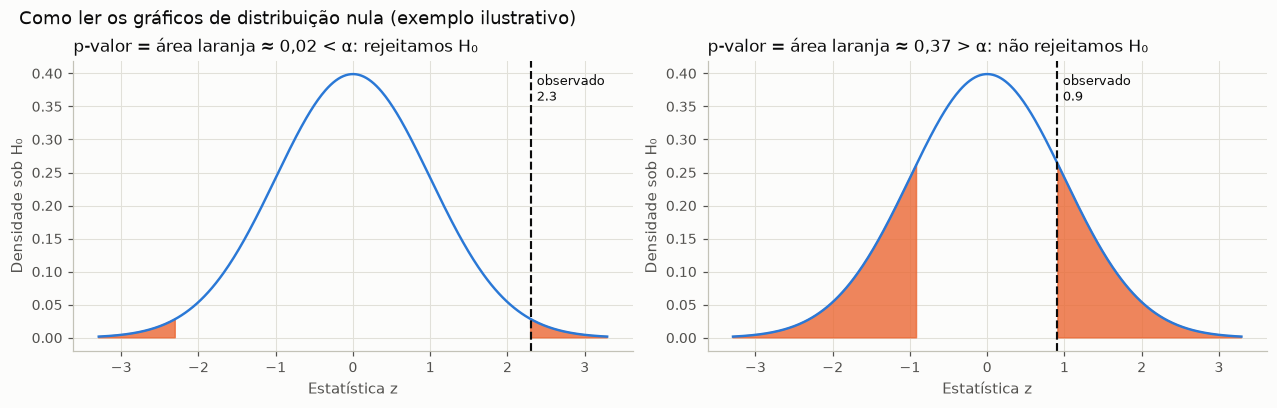

In [5]:
# Objetivo: Definir funções de gráfico reutilizadas e ilustrar a leitura de um p-valor.
def plotar_distribuicao_nula(ax, valor_observado, amostras_nulas=None, distribuicao=None,
                             cauda="direita", rotulo_estatistica="Estatística"):
    '''Desenha a distribuição de uma estatística sob H0 e marca o valor observado.

    A área sombreada corresponde ao p-valor: a probabilidade, supondo H0 verdadeira, de
    obter um valor tão ou mais extremo que o observado.

    Parâmetros:
        ax (Axes): eixo onde desenhar.
        valor_observado (float): estatística calculada nos dados reais.
        amostras_nulas (array, opcional): valores simulados sob H0 (permutação).
        distribuicao (scipy frozen dist, opcional): distribuição teórica sob H0.
        cauda (str): "direita", "esquerda" ou "bilateral".
        rotulo_estatistica (str): nome da estatística para o eixo x.

    Retorna:
        O próprio eixo recebido, já preenchido.
    '''
    def extremo(x):
        if cauda == "direita":
            return x >= valor_observado
        if cauda == "esquerda":
            return x <= valor_observado
        return np.abs(x) >= abs(valor_observado)

    if amostras_nulas is not None:
        bordas = np.histogram_bin_edges(amostras_nulas, bins=50)
        contagem, bordas = np.histogram(amostras_nulas, bins=bordas, density=True)
        centros = (bordas[:-1] + bordas[1:]) / 2
        cores = np.where(extremo(centros), LARANJA, AZUL_CLARO)
        ax.bar(centros, contagem, width=np.diff(bordas), color=cores,
               edgecolor=SUPERFICIE, linewidth=0.4)
        limites = [min(amostras_nulas.min(), valor_observado),
                   max(amostras_nulas.max(), valor_observado)]
    else:
        x = np.linspace(distribuicao.ppf(0.0005), distribuicao.ppf(0.9995), 400)
        dens = distribuicao.pdf(x)
        ax.plot(x, dens, color=AZUL, linewidth=1.6)
        ax.fill_between(x, dens, where=extremo(x), color=LARANJA, alpha=0.8)
        limites = [x.min(), x.max()]

    amplitude = limites[1] - limites[0]
    fora_da_escala = valor_observado > limites[1] or valor_observado < limites[0]
    if not fora_da_escala or amostras_nulas is not None:
        ax.axvline(valor_observado, color=TINTA, linewidth=1.4, linestyle="--")
        ax.annotate(f"observado\n{valor_observado:.3g}", (valor_observado, ax.get_ylim()[1]),
                    xytext=(4, -26), textcoords="offset points", fontsize=8.5)
    else:
        lado = 1 if valor_observado > limites[1] else 0
        seta = "→" if lado else "←"
        ax.annotate(f"observado = {valor_observado:.3g}\n{seta} muito além do gráfico",
                    (limites[lado], ax.get_ylim()[1] * 0.6), xytext=(-150 if lado else 6, 0),
                    textcoords="offset points", fontsize=8.5, color=TINTA)
    ax.set(xlabel=rotulo_estatistica, ylabel="Densidade sob H₀")
    ax.set_xlim(limites[0] - 0.05 * amplitude, limites[1] + 0.05 * amplitude)
    return ax


def plotar_qq(ax, valores, titulo):
    '''Desenha um QQ-plot contra a normal, com a reta de referência.

    Parâmetros:
        ax (Axes): eixo onde desenhar.
        valores (array): amostra a comparar com a distribuição normal.
        titulo (str): título do gráfico.

    Retorna:
        O próprio eixo recebido, já preenchido.
    '''
    (teoricos, amostra), (inclinacao, intercepto, _) = stats.probplot(valores)
    ax.scatter(teoricos, amostra, s=9, color=AZUL, alpha=0.6)
    ax.plot(teoricos, inclinacao * teoricos + intercepto, color=TINTA, linewidth=1.1)
    ax.set(title=titulo, xlabel="Quantis teóricos da normal", ylabel="Quantis da amostra")
    return ax


fig, eixos = plt.subplots(1, 2, figsize=(11.5, 3.6), constrained_layout=True)
plotar_distribuicao_nula(eixos[0], 2.3, distribuicao=stats.norm(), cauda="bilateral",
                         rotulo_estatistica="Estatística z")
eixos[0].set_title("p-valor = área laranja ≈ 0,02 < α: rejeitamos H₀")
plotar_distribuicao_nula(eixos[1], 0.9, distribuicao=stats.norm(), cauda="bilateral",
                         rotulo_estatistica="Estatística z")
eixos[1].set_title("p-valor = área laranja ≈ 0,37 > α: não rejeitamos H₀")
fig.suptitle("Como ler os gráficos de distribuição nula (exemplo ilustrativo)", x=0.01,
             ha="left", fontsize=12)
plt.show()

**Como ler:** a curva azul mostra os valores que a estatística costuma assumir **se H₀ for
verdadeira**. A linha tracejada é o valor calculado nos dados. A área laranja, além do valor
observado, é o p-valor. Se o valor observado cai numa região que H₀ quase nunca produziria (área
menor que α = 0,05), concluímos que H₀ não explica bem os dados.

### 3.2 Por que usar o dia como unidade de análise

Todo teste deste notebook supõe observações **independentes**. Medimos a autocorrelação da demanda
horária e da demanda média diária: quanto uma observação "lembra" a anterior.

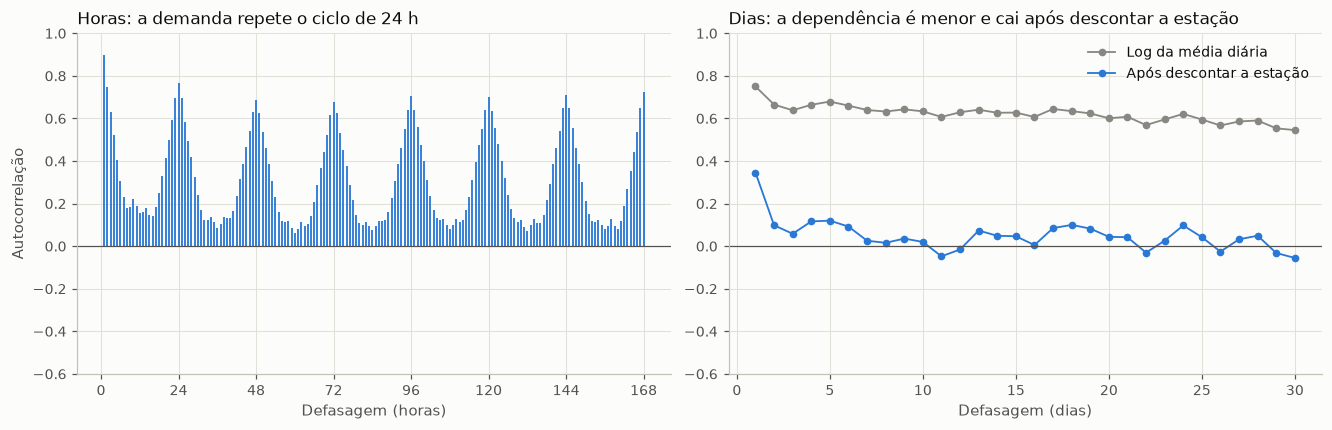

Autocorrelação horária com defasagem 1 h: 0.90; 24 h: 0.77
Autocorrelação diária com defasagem 1 dia: 0.75; após descontar a estação: 0.35


In [6]:
# Objetivo: Comparar a autocorrelação da série horária com a da série diária.
def autocorrelacoes(serie, defasagens):
    '''Calcula a autocorrelação de uma série regular para várias defasagens.

    Parâmetros:
        serie (Series): série temporal com frequência regular (pode ter NaN).
        defasagens (iterable): defasagens desejadas, em passos da série.

    Retorna:
        numpy.ndarray com uma autocorrelação por defasagem.
    '''
    return np.array([serie.autocorr(int(k)) for k in defasagens])


instantes = df_op["Date"] + pd.to_timedelta(df_op["Hour"], unit="h")
serie_horaria = pd.Series(df_op[ALVO].to_numpy(), index=instantes).sort_index().asfreq("h")
serie_diaria = df_dia["Log_Media"].asfreq("D")
residuo_diario = (serie_diaria
                  - df_dia.groupby("Seasons")["Log_Media"].transform("mean").asfreq("D"))

defas_h = np.arange(1, 24 * 7 + 1)
defas_d = np.arange(1, 31)
acf_h = autocorrelacoes(serie_horaria, defas_h)
acf_d = autocorrelacoes(serie_diaria, defas_d)
acf_r = autocorrelacoes(residuo_diario, defas_d)

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
eixos[0].vlines(defas_h, 0, acf_h, color=AZUL, linewidth=1.2)
eixos[0].set(title="Horas: a demanda repete o ciclo de 24 h", xlabel="Defasagem (horas)",
             ylabel="Autocorrelação", xticks=range(0, 169, 24), ylim=(-0.6, 1))
eixos[1].plot(defas_d, acf_d, color=CINZA, marker="o", ms=4, linewidth=1.2,
              label="Log da média diária")
eixos[1].plot(defas_d, acf_r, color=AZUL, marker="o", ms=4, linewidth=1.2,
              label="Após descontar a estação")
eixos[1].set(title="Dias: a dependência é menor e cai após descontar a estação",
             xlabel="Defasagem (dias)", ylim=(-0.6, 1))
eixos[1].legend(loc="upper right")
for ax in eixos:
    ax.axhline(0, color=TINTA_SECUNDARIA, linewidth=0.8)
plt.show()

print(f"Autocorrelação horária com defasagem 1 h: {acf_h[0]:.2f}; 24 h: {acf_h[23]:.2f}")
print(f"Autocorrelação diária com defasagem 1 dia: {acf_d[0]:.2f}; "
      f"após descontar a estação: {acf_r[0]:.2f}")

**O que observamos e a decisão tomada:**

- Na série horária, cada hora tem correlação de 0,9 com a anterior, e o padrão se repete a cada
  24 h. Tratar as ~6.800 horas como independentes superestima muito a quantidade de informação.
- No nível diário, a dependência ainda existe (o clima tem "memória" de alguns dias), mas é bem
  menor, sobretudo depois de descontar a estação, que é exatamente o que os modelos das hipóteses
  H1 e H2 fazem.

**Justificativa:** por isso, H1, H2 e H4 usam **um registro por dia** (353 dias). H3 (chuva) é uma
pergunta sobre horas, mas compara cada hora com a mesma hora do dia em condições secas, o que
neutraliza o ciclo diário. Mesmo assim, a dependência residual pode deixar os p-valores um pouco
otimistas: por isso olhamos sempre também o tamanho do efeito, e não só o p-valor.

## Seção 4 – Hipótese 1: A Demanda Difere entre as Estações?

**Hipóteses:**

- H₀: a distribuição da demanda média diária é a mesma nas quatro estações.
- H₁: pelo menos uma estação tem distribuição diferente (deslocada) das demais.

**Nível de significância:** α = 0,05.

**Teste candidato:** ANOVA de um fator, que compara médias de vários grupos. Ela supõe resíduos
normais e **variâncias iguais** entre os grupos. Verificamos as duas suposições antes de usá-la.

### 4.1 Os dados

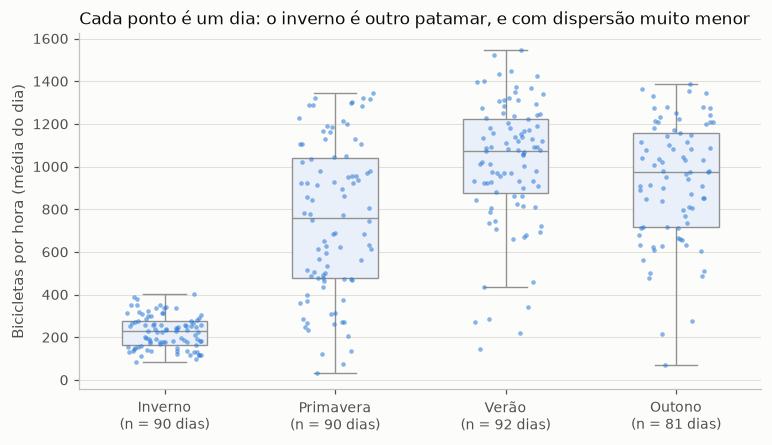

,count,mean,median,std
Seasons,,,,
Winter,90,226.2,230.7,76.2
Spring,90,751.6,760.9,358.9
Summer,92,1019.8,1073.8,292.8
Autumn,81,930.5,974.1,284.0


In [7]:
# Objetivo: Mostrar a demanda média diária de cada estação, com cada dia como um ponto.
def plotar_pontos_por_grupo(ax, df, grupo, valor, ordem, rotulos, cor=AZUL):
    '''Desenha um boxplot discreto com os pontos individuais sobrepostos.

    Parâmetros:
        ax (Axes): eixo onde desenhar.
        df (DataFrame): dados de origem.
        grupo (str): coluna categórica.
        valor (str): coluna numérica.
        ordem (list): ordem das categorias.
        rotulos (dict): nome exibido para cada categoria.
        cor (str): cor dos pontos.

    Retorna:
        O próprio eixo recebido, já preenchido.
    '''
    sns.boxplot(data=df, x=grupo, y=valor, order=ordem, ax=ax, color="#e8f0fb", width=0.5,
                showfliers=False, linewidth=0.9)
    sns.stripplot(data=df, x=grupo, y=valor, order=ordem, ax=ax, color=cor, size=3,
                  alpha=0.55, jitter=0.22)
    contagens = df[grupo].value_counts()
    ax.set_xticks(range(len(ordem)),
                  [f"{rotulos[c]}\n(n = {contagens[c]} dias)" for c in ordem])
    ax.set_xlabel("")
    return ax


fig, ax = plt.subplots(figsize=(8, 4.2))
plotar_pontos_por_grupo(ax, df_dia, "Seasons", "Media_Horaria", ORDEM_ESTACOES, NOMES_ESTACOES)
ax.set(ylabel="Bicicletas por hora (média do dia)",
       title="Cada ponto é um dia: o inverno é outro patamar, e com dispersão muito menor")
plt.show()

display(df_dia.groupby("Seasons")["Media_Horaria"]
        .agg(["count", "mean", "median", "std"]).loc[ORDEM_ESTACOES].round(1))

### 4.2 Verificação das suposições da ANOVA

- **Normalidade:** QQ-plot e teste de Shapiro-Wilk dos resíduos da ANOVA (valor de cada dia menos a
  média da sua estação). H₀ do Shapiro-Wilk: os resíduos vêm de uma normal.
- **Homogeneidade das variâncias:** teste de Levene. H₀: as quatro estações têm a mesma variância.

Testamos a escala original e a escala logarítmica, que a Etapa 1 indicou como estabilizadora da
variância.

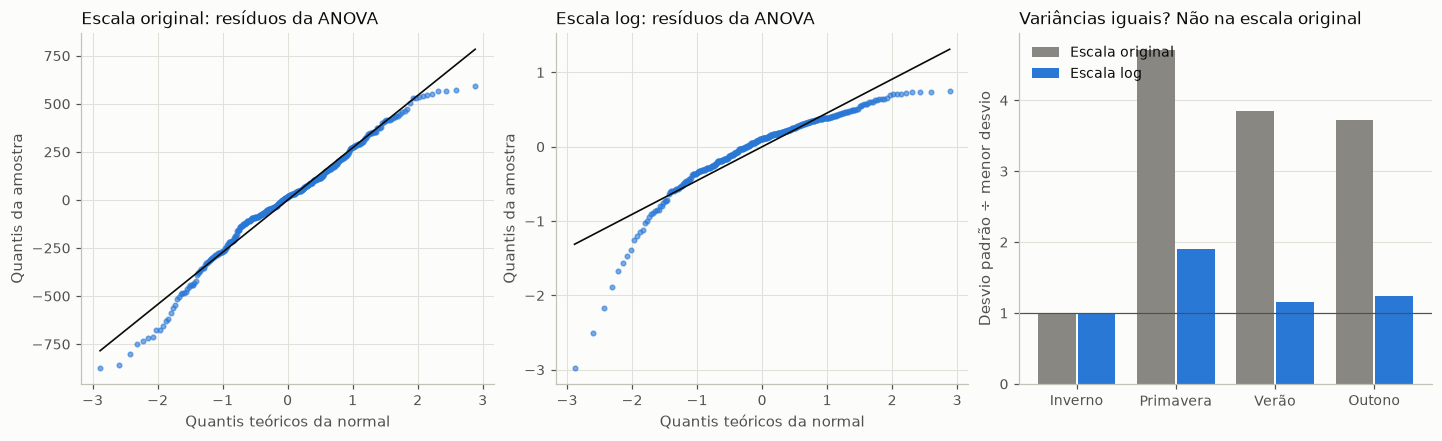

,Shapiro-Wilk (p),Levene (p),Razão maior/menor desvio padrão
Escala original,0.0001,0.0,4.7096
Escala log,0.0000,0.0,1.9010


In [8]:
# Objetivo: Verificar normalidade dos resíduos e igualdade de variâncias, nas duas escalas.
def verificar_suposicoes_anova(df, grupo, valor, ordem):
    '''Calcula os resíduos de uma ANOVA de um fator e testa normalidade e variâncias.

    Parâmetros:
        df (DataFrame): dados de origem.
        grupo (str): coluna categórica (fator).
        valor (str): coluna numérica (resposta).
        ordem (list): categorias do fator.

    Retorna:
        Tupla (residuos, dicionário com os p-valores de Shapiro-Wilk e de Levene).
    '''
    residuos = df[valor] - df.groupby(grupo)[valor].transform("mean")
    amostras = [df.loc[df[grupo] == g, valor] for g in ordem]
    return residuos, {
        "Shapiro-Wilk (p)": stats.shapiro(residuos).pvalue,
        "Levene (p)": stats.levene(*amostras).pvalue,
        "Razão maior/menor desvio padrão": max(a.std() for a in amostras)
        / min(a.std() for a in amostras),
    }


resultados_suposicoes = {}
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.9), constrained_layout=True)
for ax, (nome, coluna) in zip(eixos[:2], [("Escala original", "Media_Horaria"),
                                         ("Escala log", "Log_Media")]):
    residuos, testes = verificar_suposicoes_anova(df_dia, "Seasons", coluna, ORDEM_ESTACOES)
    resultados_suposicoes[nome] = testes
    plotar_qq(ax, residuos, f"{nome}: resíduos da ANOVA")

desvios = pd.DataFrame({
    "Escala original": df_dia.groupby("Seasons")["Media_Horaria"].std(),
    "Escala log": df_dia.groupby("Seasons")["Log_Media"].std(),
}).loc[ORDEM_ESTACOES]
desvios_rel = desvios / desvios.min()
posicoes = np.arange(len(ORDEM_ESTACOES))
eixos[2].bar(posicoes - 0.2, desvios_rel["Escala original"], 0.38, color=CINZA,
             label="Escala original")
eixos[2].bar(posicoes + 0.2, desvios_rel["Escala log"], 0.38, color=AZUL, label="Escala log")
eixos[2].axhline(1, color=TINTA_SECUNDARIA, linewidth=0.8)
eixos[2].set(xticks=posicoes, xticklabels=[NOMES_ESTACOES[s] for s in ORDEM_ESTACOES],
             ylabel="Desvio padrão ÷ menor desvio",
             title="Variâncias iguais? Não na escala original")
eixos[2].legend(loc="upper left")
eixos[2].grid(axis="x", visible=False)
plt.show()

display(pd.DataFrame(resultados_suposicoes).T.round(4))

**O que observamos:**

- **Escala original:** o desvio padrão do verão é cerca de 4 vezes o do inverno, e o Levene rejeita
  variâncias iguais com folga. A suposição central da ANOVA clássica falha.
- **Escala log:** as variâncias ficam bem mais parecidas, mas o Levene ainda as rejeita, e o
  QQ-plot mostra uma **cauda esquerda longa**: são os dias de chuva, com demanda muito abaixo do
  normal da estação. O Shapiro-Wilk rejeita a normalidade nas duas escalas.

**Escolha do teste:** como nenhuma transformação resolve as duas suposições, usamos o
**teste de Kruskal-Wallis**, a alternativa não paramétrica à ANOVA de um fator. Ele trabalha com os
**postos** (posições ordenadas) dos dias, então não exige normalidade e é pouco afetado pelos dias
de chuva extremos. Como os formatos das distribuições diferem entre estações, interpretamos uma
rejeição como "pelo menos uma estação tende a ter valores maiores que outra", e não como
"as medianas diferem". Como confirmação, também rodamos a ANOVA de Welch, que tolera variâncias
diferentes.

### 4.3 Teste de Kruskal-Wallis

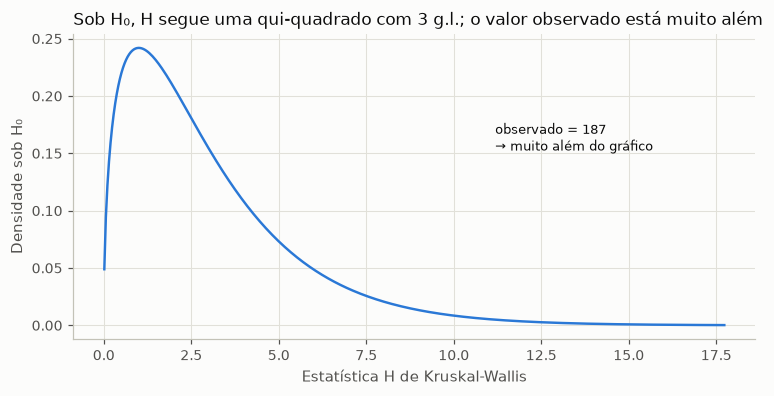

,Estatística,Graus de liberdade,p-valor
Kruskal-Wallis,H = 187.1,3,2.6e-40
ANOVA de Welch (log),F = 289.6,3 e 190,1.7e-70


Tamanho do efeito (épsilon² de Kruskal-Wallis): 0.53


In [9]:
# Objetivo: Aplicar o Kruskal-Wallis, a ANOVA de Welch e medir o tamanho do efeito.
amostras_estacao = [df_dia.loc[df_dia["Seasons"] == s, "Media_Horaria"]
                    for s in ORDEM_ESTACOES]
h_kw, p_kw = stats.kruskal(*amostras_estacao)
n_dias, k_grupos = len(df_dia), len(ORDEM_ESTACOES)
epsilon2 = (h_kw - k_grupos + 1) / (n_dias - k_grupos)
welch = anova_oneway(df_dia["Log_Media"], df_dia["Seasons"], use_var="unequal")

fig, ax = plt.subplots(figsize=(8, 3.6))
plotar_distribuicao_nula(ax, h_kw, distribuicao=stats.chi2(k_grupos - 1),
                         rotulo_estatistica="Estatística H de Kruskal-Wallis")
ax.set_title("Sob H₀, H segue uma qui-quadrado com 3 g.l.; o valor observado está muito além")
plt.show()

tabela_h1 = pd.DataFrame({
    "Estatística": [f"H = {h_kw:.1f}", f"F = {welch.statistic:.1f}"],
    "Graus de liberdade": [k_grupos - 1, f"3 e {welch.df[1]:.0f}"],
    "p-valor": [f"{p_kw:.1e}", f"{welch.pvalue:.1e}"],
}, index=["Kruskal-Wallis", "ANOVA de Welch (log)"])
display(tabela_h1)
print(f"Tamanho do efeito (épsilon² de Kruskal-Wallis): {epsilon2:.2f}")

O **épsilon²** mede a fração da variação dos postos explicada pela estação (de 0 a 1). Valores
acima de 0,26 costumam ser considerados efeitos grandes, então a estação explica uma parte
expressiva da variação da demanda diária.

### 4.4 Quais estações diferem entre si?

O Kruskal-Wallis diz apenas que *alguma* estação difere. Para localizar as diferenças, comparamos
cada par com o teste de **Mann-Whitney** (a versão de dois grupos do Kruskal-Wallis). Como fazemos
6 comparações, a chance de algum falso positivo aumenta; corrigimos os p-valores pelo método de
**Holm**, que controla essa chance em 5%.

Como tamanho de efeito, usamos a **probabilidade de superioridade**: a chance de um dia sorteado da
estação da linha ter demanda maior que um dia sorteado da estação da coluna (0,5 = nenhuma
diferença).

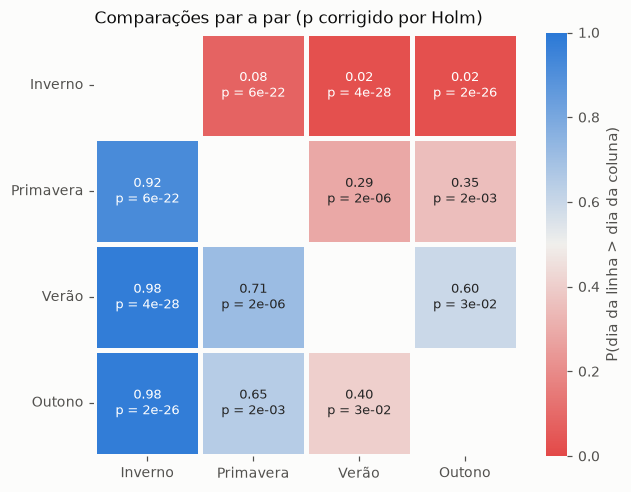

,A,B,U,p_bruto,P(A > B),p_Holm,Rejeita H0
0,Inverno,Primavera,636.000000,1.6e-22,0.080000,6.3e-22,True
1,Inverno,Verão,173.000000,6.2e-29,0.020000,3.7e-28,True
2,Inverno,Outono,161.000000,4.4e-27,0.020000,2.2e-26,True
3,Primavera,Verão,2378.000000,7.2e-07,0.290000,2.1e-06,True
4,Primavera,Outono,2586.000000,1.1e-03,0.350000,2.1e-03,True
5,Verão,Outono,4447.000000,2.8e-02,0.600000,2.8e-02,True


In [10]:
# Objetivo: Comparar as estações par a par com Mann-Whitney e correção de Holm.
def comparar_pares(df, grupo, valor, ordem):
    '''Aplica Mann-Whitney a todos os pares de categorias, com correção de Holm.

    Parâmetros:
        df (DataFrame): dados de origem.
        grupo (str): coluna categórica.
        valor (str): coluna numérica.
        ordem (list): categorias, na ordem desejada.

    Retorna:
        DataFrame com uma linha por par, contendo U, p bruto, p corrigido e a
        probabilidade de superioridade P(A > B).
    '''
    linhas = []
    for i, a in enumerate(ordem):
        for b in ordem[i + 1:]:
            x, y = df.loc[df[grupo] == a, valor], df.loc[df[grupo] == b, valor]
            teste = stats.mannwhitneyu(x, y, alternative="two-sided")
            linhas.append({"A": a, "B": b, "U": teste.statistic, "p_bruto": teste.pvalue,
                           "P(A > B)": teste.statistic / (len(x) * len(y))})
    pares = pd.DataFrame(linhas)
    pares["p_Holm"] = multipletests(pares["p_bruto"], method="holm")[1]
    pares["Rejeita H0"] = pares["p_Holm"] < ALFA
    return pares


pares_estacao = comparar_pares(df_dia, "Seasons", "Media_Horaria", ORDEM_ESTACOES)

matriz = pd.DataFrame(np.nan, index=ORDEM_ESTACOES, columns=ORDEM_ESTACOES)
anotacoes = matriz.astype(object).fillna("")
for _, par in pares_estacao.iterrows():
    for linha, coluna, prob in [(par["A"], par["B"], par["P(A > B)"]),
                                (par["B"], par["A"], 1 - par["P(A > B)"])]:
        matriz.loc[linha, coluna] = prob
        anotacoes.loc[linha, coluna] = f"{prob:.2f}\np = {par['p_Holm']:.0e}"

fig, ax = plt.subplots(figsize=(6.6, 5))
mapa = sns.color_palette("blend:#e34948,#f0efec,#2a78d6", as_cmap=True)
sns.heatmap(matriz, annot=anotacoes, fmt="", cmap=mapa, vmin=0, vmax=1, ax=ax, square=True,
            linewidths=2, linecolor=SUPERFICIE, annot_kws={"size": 8.5},
            cbar_kws={"label": "P(dia da linha > dia da coluna)"})
rotulos = [NOMES_ESTACOES[s] for s in ORDEM_ESTACOES]
ax.set_xticklabels(rotulos)
ax.set_yticklabels(rotulos, rotation=0)
ax.set(title="Comparações par a par (p corrigido por Holm)", xlabel="", ylabel="")
ax.grid(False)
plt.show()

display(pares_estacao.assign(A=pares_estacao["A"].map(NOMES_ESTACOES),
                             B=pares_estacao["B"].map(NOMES_ESTACOES))
        .round({"P(A > B)": 2}).style.format({"p_bruto": "{:.1e}", "p_Holm": "{:.1e}"}))

**Como ler:** azul forte indica que a estação da linha quase sempre supera a da coluna; vermelho, o
contrário; branco, equilíbrio.

### 4.5 Conclusão da Hipótese 1

| Estatística | Valor |
|---|---|
| Teste | Kruskal-Wallis (confirmado pela ANOVA de Welch na escala log) |
| H de Kruskal-Wallis | ver tabela da Seção 4.3 (≈ 187, 3 g.l.) |
| p-valor | < 10⁻³⁹ |
| Tamanho do efeito (ε²) | ≈ 0,53 (grande) |
| Decisão | **Rejeitamos H₀** |

**Na prática:** a demanda difere entre as estações, e o efeito é grande. O inverno é o caso
extremo: um dia de inverno sorteado ao acaso tem demanda menor que um dia de verão em quase 100% das
comparações. As comparações par a par mostram que **todos** os pares diferem após a correção de
Holm, na ordem inverno < primavera < outono < verão. O par outono × verão é o mais próximo:
um dia de verão supera um de outono em 60% das comparações (p corrigido ≈ 0,03). Para a Etapa 3, isso confirma que `Seasons` (ou `Month`)
deve entrar no modelo, sem esquecer que boa parte desse efeito pode ser explicada pela temperatura.

## Seção 5 – Hipótese 2: Feriados Mudam a Demanda, Considerando a Estação?

Na Etapa 1, os feriados pareciam cortar a demanda pela metade, mas 47% das horas de feriado estão no
inverno, contra 24% das demais. A **estação é uma variável de confusão**: ela afeta a demanda e,
ao mesmo tempo, a chance de um dia ser feriado. A pergunta interessante, portanto, é se o feriado
tem efeito **depois de descontar a estação**.

**Hipóteses:**

- H₀: dentro de uma mesma estação, feriados e não feriados têm a mesma demanda média diária (na
  escala log).
- H₁: dentro de uma mesma estação, a demanda dos feriados é diferente.

**Nível de significância:** α = 0,05.

### 5.1 O teste ingênuo e os dados

Teste ingênuo (Mann-Whitney com 6774 horas, sem considerar a estação): p = 4.8e-14


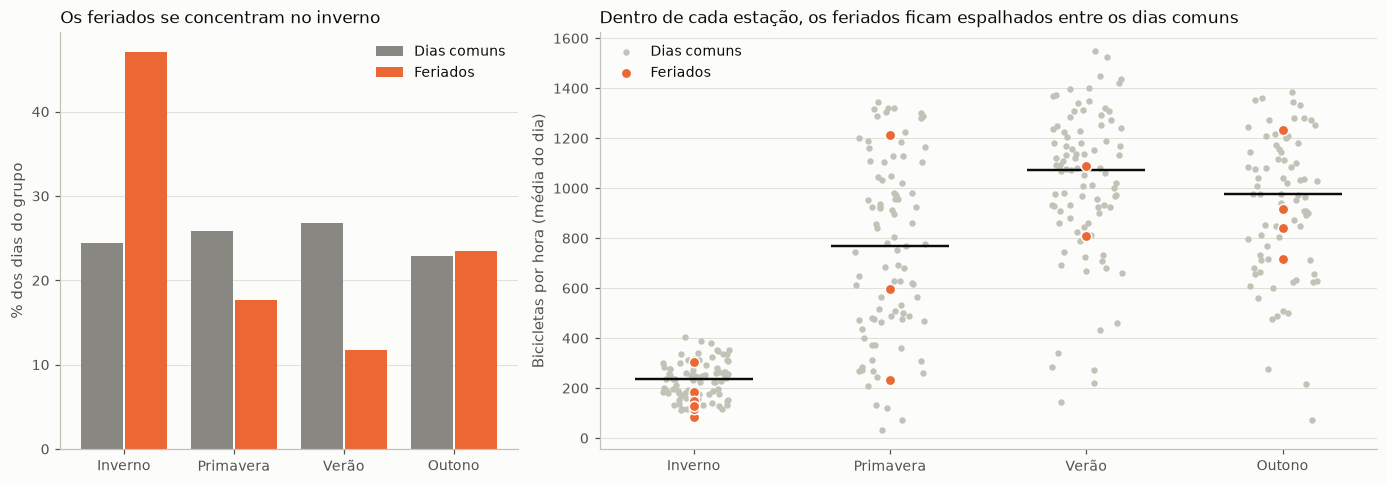

count             median           
Holiday Holiday No Holiday Holiday No Holiday
Seasons                                      
Winter        8         82   141.0      236.0
Spring        3         87   596.0      771.0
Summer        2         90   949.0     1074.0
Autumn        4         77   878.0      975.0

In [11]:
# Objetivo: Rodar o teste ingênuo (horas, sem estação) e visualizar a confusão com a estação.
horas_feriado = df_op.loc[df_op["Holiday"] == "Holiday", ALVO]
horas_normais = df_op.loc[df_op["Holiday"] == "No Holiday", ALVO]
teste_ingenuo = stats.mannwhitneyu(horas_feriado, horas_normais, alternative="two-sided")
print(f"Teste ingênuo (Mann-Whitney com {len(df_op)} horas, sem considerar a estação): "
      f"p = {teste_ingenuo.pvalue:.1e}")

fig, eixos = plt.subplots(1, 2, figsize=(12.5, 4.3), width_ratios=[1, 1.7],
                          constrained_layout=True)
composicao = (pd.crosstab(df_dia["Holiday"], df_dia["Seasons"], normalize="index")
              .loc[["No Holiday", "Holiday"], ORDEM_ESTACOES] * 100)
posicoes = np.arange(len(ORDEM_ESTACOES))
eixos[0].bar(posicoes - 0.2, composicao.loc["No Holiday"], 0.38, color=CINZA,
             label="Dias comuns")
eixos[0].bar(posicoes + 0.2, composicao.loc["Holiday"], 0.38, color=LARANJA, label="Feriados")
eixos[0].set(xticks=posicoes, xticklabels=[NOMES_ESTACOES[s] for s in ORDEM_ESTACOES],
             ylabel="% dos dias do grupo",
             title="Os feriados se concentram no inverno")
eixos[0].legend(loc="upper right")
eixos[0].grid(axis="x", visible=False)

comuns = df_dia[df_dia["Holiday"] == "No Holiday"]
feriados = df_dia[df_dia["Holiday"] == "Holiday"]
mapa_x = {s: i for i, s in enumerate(ORDEM_ESTACOES)}
deslocamento = rng.uniform(-0.18, 0.18, len(comuns))
eixos[1].scatter(comuns["Seasons"].map(mapa_x) + deslocamento, comuns["Media_Horaria"], s=10,
                 color=CINZA_CLARO, label="Dias comuns")
eixos[1].scatter(feriados["Seasons"].map(mapa_x), feriados["Media_Horaria"], s=46,
                 color=LARANJA, edgecolor=SUPERFICIE, linewidth=1, zorder=3, label="Feriados")
for estacao, pos in mapa_x.items():
    mediana = comuns.loc[comuns["Seasons"] == estacao, "Media_Horaria"].median()
    eixos[1].hlines(mediana, pos - 0.3, pos + 0.3, color=TINTA, linewidth=1.6)
eixos[1].set(xticks=posicoes, xticklabels=[NOMES_ESTACOES[s] for s in ORDEM_ESTACOES],
             ylabel="Bicicletas por hora (média do dia)",
             title="Dentro de cada estação, os feriados ficam espalhados entre os dias comuns")
eixos[1].legend(loc="upper left")
eixos[1].grid(axis="x", visible=False)
plt.show()

display(df_dia.groupby(["Seasons", "Holiday"])["Media_Horaria"].agg(["count", "median"])
        .unstack().loc[ORDEM_ESTACOES].round(0))

**O que observamos:** o teste ingênuo dá um p-valor minúsculo. Mas o gráfico da direita (a linha
preta é a mediana dos dias comuns) mostra que, **dentro de cada estação**, os feriados se misturam
aos dias comuns: alguns ficam acima, outros abaixo. São só 17 dias de feriado em operação, com
apenas 2 no verão.

### 5.2 Teste escolhido: ANOVA de dois fatores

A ANOVA de dois fatores (vista em aula com o exemplo "veneno e antídoto") avalia o efeito de
`Holiday` **controlando** `Seasons`. Usamos a resposta em log, que deixa as variâncias mais
próximas (Seção 4.2) e transforma o efeito em uma variação percentual. Como o desenho é
**desbalanceado** (pouquíssimos feriados), usamos somas de quadrados do tipo II, que avaliam cada
fator descontando o outro. Primeiro verificamos se há interação (o efeito do feriado muda conforme a
estação).

In [12]:
# Objetivo: Ajustar a ANOVA de dois fatores, com e sem interação.
modelo_interacao = smf.ols("Log_Media ~ C(Seasons) * C(Holiday)", data=df_dia).fit()
modelo_aditivo = smf.ols("Log_Media ~ C(Seasons) + C(Holiday, Treatment('No Holiday'))",
                         data=df_dia).fit()

print("ANOVA com interação (tipo II):")
display(sm.stats.anova_lm(modelo_interacao, typ=2).round(4))
anova_h2 = sm.stats.anova_lm(modelo_aditivo, typ=2)
anova_h2.index = ["Seasons", "Holiday", "Resíduo"]
print("ANOVA aditiva (tipo II):")
display(anova_h2.round(4))

termo_feriado = "C(Holiday, Treatment('No Holiday'))[T.Holiday]"
efeito_log = modelo_aditivo.params[termo_feriado]
ic_log = modelo_aditivo.conf_int().loc[termo_feriado]
print(f"Efeito estimado do feriado: {np.expm1(efeito_log):+.1%} na demanda "
      f"(IC 95%: {np.expm1(ic_log[0]):+.1%} a {np.expm1(ic_log[1]):+.1%})")

ANOVA com interação (tipo II):


,sum_sq,df,F,PR(>F)
C(Seasons),123.7519,3.0,172.0491,0.0000
C(Holiday),0.6092,1.0,2.5407,0.1119
C(Seasons):C(Holiday),0.5746,3.0,0.7989,0.4952
Residual,82.7175,345.0,NaN,NaN


ANOVA aditiva (tipo II):


,sum_sq,df,F,PR(>F)
Seasons,123.7519,3.0,172.3479,0.0000
Holiday,0.6092,1.0,2.5451,0.1115
Resíduo,83.2921,348.0,NaN,NaN


Efeito estimado do feriado: -17.8% na demanda (IC 95%: -35.4% a +4.7%)


A interação não é significativa (e, com 2 feriados no verão, nem poderia ser estimada com
precisão), então seguimos com o **modelo aditivo**. Antes de interpretar o p-valor de `Holiday`,
verificamos as suposições da ANOVA nos resíduos desse modelo.

### 5.3 Verificação das suposições

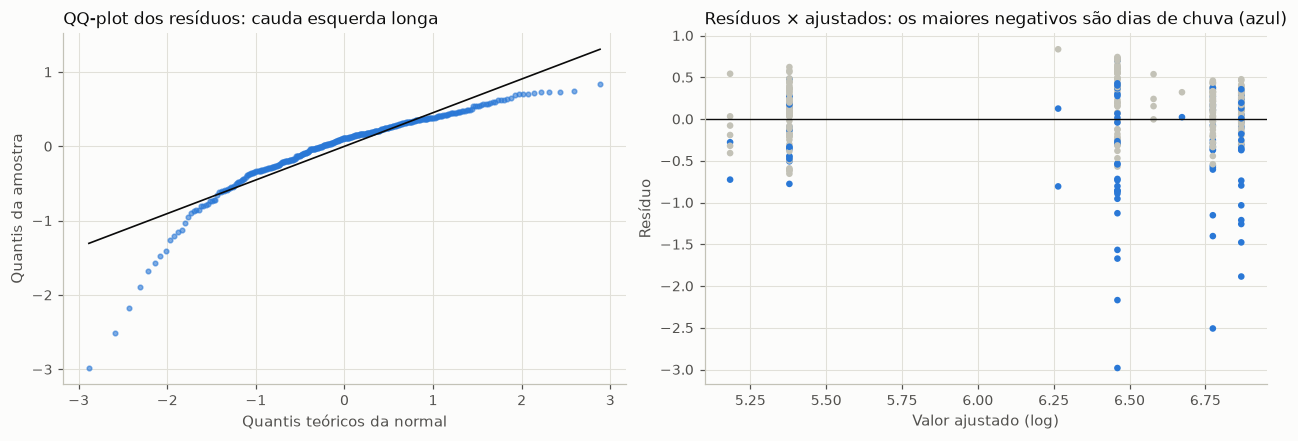

,valor
Shapiro-Wilk dos resíduos (p),0.0000
Levene entre estações (p),0.0000
Levene feriado × comum (p),0.9751


In [13]:
# Objetivo: Verificar normalidade e homogeneidade dos resíduos da ANOVA de dois fatores.
residuos_h2 = modelo_aditivo.resid
ajustados_h2 = modelo_aditivo.fittedvalues

fig, eixos = plt.subplots(1, 2, figsize=(11.5, 3.9), constrained_layout=True)
plotar_qq(eixos[0], residuos_h2, "QQ-plot dos resíduos: cauda esquerda longa")
cores = np.where(df_dia["Chuva_Total"] > 0, AZUL, CINZA_CLARO)
eixos[1].scatter(ajustados_h2, residuos_h2, s=11, c=cores)
eixos[1].axhline(0, color=TINTA, linewidth=0.9)
eixos[1].set(xlabel="Valor ajustado (log)", ylabel="Resíduo",
             title="Resíduos × ajustados: os maiores negativos são dias de chuva (azul)")
plt.show()

suposicoes_h2 = pd.Series({
    "Shapiro-Wilk dos resíduos (p)": stats.shapiro(residuos_h2).pvalue,
    "Levene entre estações (p)": stats.levene(
        *[residuos_h2[df_dia["Seasons"] == s] for s in ORDEM_ESTACOES]).pvalue,
    "Levene feriado × comum (p)": stats.levene(
        residuos_h2[df_dia["Holiday"] == "Holiday"],
        residuos_h2[df_dia["Holiday"] == "No Holiday"]).pvalue,
})
display(suposicoes_h2.to_frame("valor").style.format("{:.4f}"))

**O que observamos:** a normalidade dos resíduos falha (cauda esquerda formada pelos dias de
chuva), e as variâncias diferem entre estações. Entre feriados e dias comuns, porém, as variâncias
são compatíveis. Com 353 dias, a ANOVA costuma ser razoavelmente robusta à falta de normalidade,
mas o grupo de feriados é muito pequeno (17 dias), justamente o caso em que essa robustez é menos
garantida.

**Justificativa – teste de confirmação:** usamos um **teste de permutação estratificado**, que não
supõe normalidade. A lógica: se H₀ for verdadeira, o rótulo "feriado" é irrelevante, e trocar
aleatoriamente quais dias são feriados **dentro de cada estação** não deveria mudar nada. Repetimos
essa troca 10.000 vezes e vemos com que frequência surge uma diferença tão grande quanto a real.
Permutar dentro da estação preserva o número de feriados por estação, mantendo o controle da
variável de confusão.

### 5.4 Teste de permutação estratificado

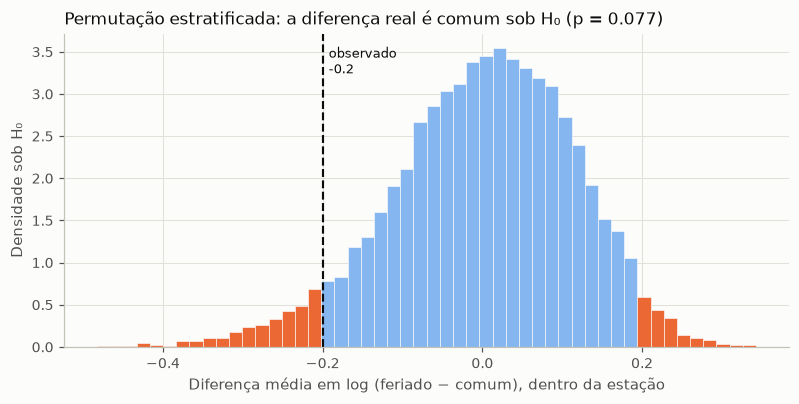

Diferença observada: -0.200 em log = -18.1% na demanda


In [14]:
# Objetivo: Definir o teste de permutação estratificado e aplicá-lo ao efeito do feriado.
def diferenca_estratificada(valores, rotulos, estratos):
    '''Calcula a diferença média (grupo 1 - grupo 0) dentro dos estratos.

    A diferença de cada estrato é ponderada pelo número de observações do grupo 1 nele.

    Parâmetros:
        valores (ndarray): resposta numérica.
        rotulos (ndarray): 1 para o grupo de interesse, 0 para os demais.
        estratos (ndarray): código do estrato de cada observação.

    Retorna:
        float com a diferença média ponderada.
    '''
    soma, peso = 0.0, 0
    for estrato in np.unique(estratos):
        no_estrato = estratos == estrato
        grupo_1 = valores[no_estrato & (rotulos == 1)]
        if len(grupo_1) == 0:
            continue
        grupo_0 = valores[no_estrato & (rotulos == 0)]
        soma += len(grupo_1) * (grupo_1.mean() - grupo_0.mean())
        peso += len(grupo_1)
    return soma / peso


def permutar_dentro_dos_estratos(rotulos, estratos, gerador):
    '''Embaralha os rótulos separadamente dentro de cada estrato.

    Parâmetros:
        rotulos (ndarray): rótulos originais.
        estratos (ndarray): código do estrato de cada observação.
        gerador (numpy.random.Generator): gerador aleatório com semente fixa.

    Retorna:
        ndarray com os rótulos embaralhados.
    '''
    embaralhados = rotulos.copy()
    for estrato in np.unique(estratos):
        posicoes = np.flatnonzero(estratos == estrato)
        embaralhados[posicoes] = gerador.permutation(rotulos[posicoes])
    return embaralhados


def teste_permutacao_estratificado(valores, rotulos, estratos, n_permutacoes, gerador):
    '''Testa a diferença entre grupos dentro de estratos por permutação (bilateral).

    Parâmetros:
        valores (ndarray): resposta numérica.
        rotulos (ndarray): 1 para o grupo de interesse, 0 para os demais.
        estratos (ndarray): código do estrato de cada observação.
        n_permutacoes (int): número de permutações.
        gerador (numpy.random.Generator): gerador aleatório com semente fixa.

    Retorna:
        Tupla (diferença observada, diferenças sob H0, p-valor bilateral).
    '''
    observado = diferenca_estratificada(valores, rotulos, estratos)
    nulas = np.array([
        diferenca_estratificada(valores, permutar_dentro_dos_estratos(rotulos, estratos,
                                                                     gerador), estratos)
        for _ in range(n_permutacoes)
    ])
    p_valor = (1 + np.sum(np.abs(nulas) >= abs(observado))) / (n_permutacoes + 1)
    return observado, nulas, p_valor


dif_feriado, nulas_feriado, p_perm_feriado = teste_permutacao_estratificado(
    df_dia["Log_Media"].to_numpy(),
    (df_dia["Holiday"] == "Holiday").astype(int).to_numpy(),
    df_dia["Seasons"].to_numpy(),
    N_PERMUTACOES, rng,
)

fig, ax = plt.subplots(figsize=(8.5, 3.7))
plotar_distribuicao_nula(ax, dif_feriado, amostras_nulas=nulas_feriado, cauda="bilateral",
                         rotulo_estatistica="Diferença média em log (feriado − comum), "
                                            "dentro da estação")
ax.set_title(f"Permutação estratificada: a diferença real é comum sob H₀ "
             f"(p = {p_perm_feriado:.3f})")
plt.show()

print(f"Diferença observada: {dif_feriado:.3f} em log = {np.expm1(dif_feriado):+.1%} "
      f"na demanda")

### 5.5 Conclusão da Hipótese 2

| Abordagem | Unidade | Controla a estação? | p-valor |
|---|---|---|---|
| Mann-Whitney ingênuo | 6.774 horas | Não | ver Seção 5.1 (≈ 10⁻¹⁴) |
| ANOVA de dois fatores (log) | 353 dias | Sim | ver tabela da Seção 5.2 (≈ 0,11) |
| Permutação estratificada | 353 dias | Sim | ver Seção 5.4 (≈ 0,08) |

**Decisão:** com α = 0,05, **não rejeitamos H₀**. Depois de considerar a estação, não há evidência
de que os feriados mudem a demanda média diária.

**Na prática:** a forte queda do teste ingênuo é, em grande parte, um efeito de **composição**:
feriados caem mais no inverno, e o inverno tem pouca demanda. O teste ingênuo erra duas vezes:
ignora a variável de confusão e trata 332 horas de feriado como independentes, quando elas vêm de
apenas 17 dias.

**Cuidado – "não rejeitar" não é "provar que não há efeito".** O intervalo de confiança do efeito
(Seção 5.2) vai de uma queda considerável até um pequeno aumento: com só 17 feriados, o teste tem
pouco poder para detectar efeitos moderados. A leitura honesta é que o efeito do feriado, se existe,
é bem menor que o sugerido pela comparação bruta. Para a Etapa 3, `Holiday` é candidata fraca, e a
ANOVA do modelo dirá se ela contribui na presença das demais variáveis (por exemplo, em interação
com a hora, já que feriados perdem os picos de deslocamento).

## Seção 6 – Hipótese 3: A Chuva Reduz a Demanda na Mesma Hora e Estação?

A correlação de Pearson entre `Rainfall` e a demanda é só −0,14. Mas comparar todas as horas com e
sem chuva mistura outros fatores: a chuva pode cair mais em certas horas ou estações. Para isolar o
efeito, comparamos a chuva com **a mesma hora do dia, na mesma estação**.

**Hipóteses:**

- H₀: em cada combinação estação × hora, a demanda típica com chuva é igual à demanda sem chuva (a
  mediana das diferenças é zero).
- H₁: a demanda com chuva é **menor** (teste unilateral, pois a Etapa 1 e o bom senso indicam a
  direção).

**Nível de significância:** α = 0,05.

### 6.1 Montagem dos pares

**Justificativa.** Cada par é uma célula estação × hora (por exemplo, "verão, 18h"). Nela, comparamos
a mediana das horas com chuva com a mediana das horas secas. Exigimos **pelo menos 3 horas com
chuva** na célula, para que a mediana não dependa de um único registro. Usamos a razão em log
(log da mediana com chuva − log da mediana seca), porque uma queda de 100 bicicletas significa muito
mais às 4h do que às 18h.

In [15]:
# Objetivo: Montar os pares (estação × hora) de demanda com e sem chuva.
MIN_HORAS_CHUVA = 3


def montar_pares_chuva(df, minimo_chuva):
    '''Calcula a demanda mediana com e sem chuva em cada combinação de estação e hora.

    Parâmetros:
        df (DataFrame): dados horários de operação, com Is_Rainy.
        minimo_chuva (int): mínimo de horas chuvosas para a célula ser usada.

    Retorna:
        DataFrame com uma linha por célula válida e a razão em log entre as medianas.
    '''
    resumo = (df.groupby(["Seasons", "Hour", "Is_Rainy"])[ALVO]
              .agg(["median", "size"]).unstack("Is_Rainy"))
    pares = pd.DataFrame({
        "Mediana_Seca": resumo[("median", 0)],
        "Mediana_Chuva": resumo[("median", 1)],
        "Horas_Chuva": resumo[("size", 1)],
    }).dropna()
    pares = pares[pares["Horas_Chuva"] >= minimo_chuva].copy()
    pares["Log_Razao"] = np.log(pares["Mediana_Chuva"]) - np.log(pares["Mediana_Seca"])
    return pares


pares_chuva = montar_pares_chuva(df_op, MIN_HORAS_CHUVA)
print("Células estação × hora possíveis: 96 | com pelo menos "
      f"{MIN_HORAS_CHUVA} horas de chuva: {len(pares_chuva)}")
print("Células por estação:", pares_chuva.groupby("Seasons").size()
      .reindex(ORDEM_ESTACOES).to_dict())
display(pares_chuva.head().round(2))

Células estação × hora possíveis: 96 | com pelo menos 3 horas de chuva: 64
Células por estação: {'Winter': 6, 'Spring': 23, 'Summer': 24, 'Autumn': 11}


Mediana_Seca  Mediana_Chuva  Horas_Chuva  Log_Razao
Seasons Hour                                                     
Autumn  3            243.0           78.0          5.0      -1.14
        4            167.0          188.0          3.0       0.12
        6            398.0          194.0          3.0      -0.72
        8           1699.0          208.0          5.0      -2.10
        9            966.0           72.5         10.0      -2.59

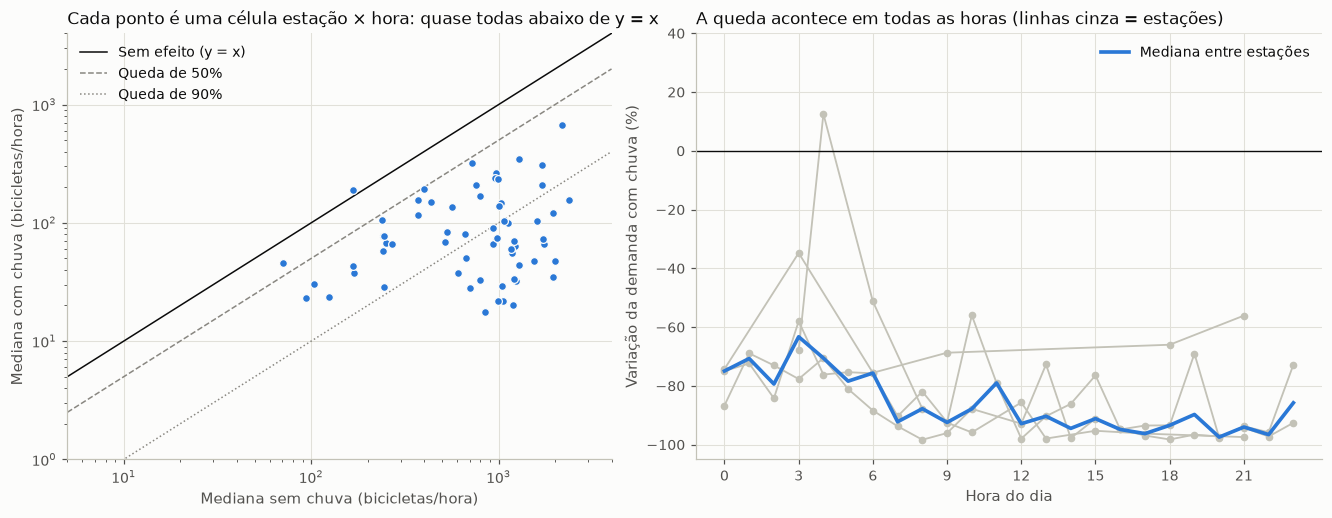

In [16]:
# Objetivo: Visualizar cada par: demanda seca (x) contra demanda com chuva (y).
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6), width_ratios=[1, 1.15],
                          constrained_layout=True)
limites = np.array([5, 4000])
eixos[0].plot(limites, limites, color=TINTA, linewidth=1, label="Sem efeito (y = x)")
eixos[0].plot(limites, 0.5 * limites, color=CINZA, linewidth=1, linestyle="--",
              label="Queda de 50%")
eixos[0].plot(limites, 0.1 * limites, color=CINZA, linewidth=1, linestyle=":",
              label="Queda de 90%")
eixos[0].scatter(pares_chuva["Mediana_Seca"], pares_chuva["Mediana_Chuva"], s=26,
                 color=AZUL, edgecolor=SUPERFICIE, linewidth=0.8, zorder=3)
eixos[0].set(xscale="log", yscale="log", xlim=limites, ylim=(1, 4000),
             xlabel="Mediana sem chuva (bicicletas/hora)",
             ylabel="Mediana com chuva (bicicletas/hora)",
             title="Cada ponto é uma célula estação × hora: quase todas abaixo de y = x")
eixos[0].legend(loc="upper left")

perfil = pares_chuva.reset_index()
for estacao in ORDEM_ESTACOES:
    dados = perfil[perfil["Seasons"] == estacao]
    eixos[1].plot(dados["Hour"], 100 * np.expm1(dados["Log_Razao"]), marker="o", ms=4,
                  linewidth=1.2, color=CINZA_CLARO)
mediana_hora = perfil.groupby("Hour")["Log_Razao"].median()
eixos[1].plot(mediana_hora.index, 100 * np.expm1(mediana_hora), color=AZUL, linewidth=2.4,
              label="Mediana entre estações")
eixos[1].axhline(0, color=TINTA, linewidth=0.9)
eixos[1].set(xlabel="Hora do dia", ylabel="Variação da demanda com chuva (%)",
             xticks=range(0, 24, 3), ylim=(-105, 40),
             title="A queda acontece em todas as horas (linhas cinza = estações)")
eixos[1].legend(loc="upper right")
plt.show()

### 6.2 Escolha do teste e verificação das suposições

Os dados são **pareados** (cada célula tem um valor seco e um chuvoso). O teste t pareado exigiria
diferenças com distribuição normal; o **teste de postos sinalizados de Wilcoxon** só exige que as
diferenças sejam **simétricas** em torno da mediana. Verificamos as duas coisas. Como
confirmação, usamos também o **teste do sinal**, que não exige nem simetria: ele apenas conta
quantas células tiveram queda e compara com uma moeda honesta (50%) por meio da distribuição
binomial.

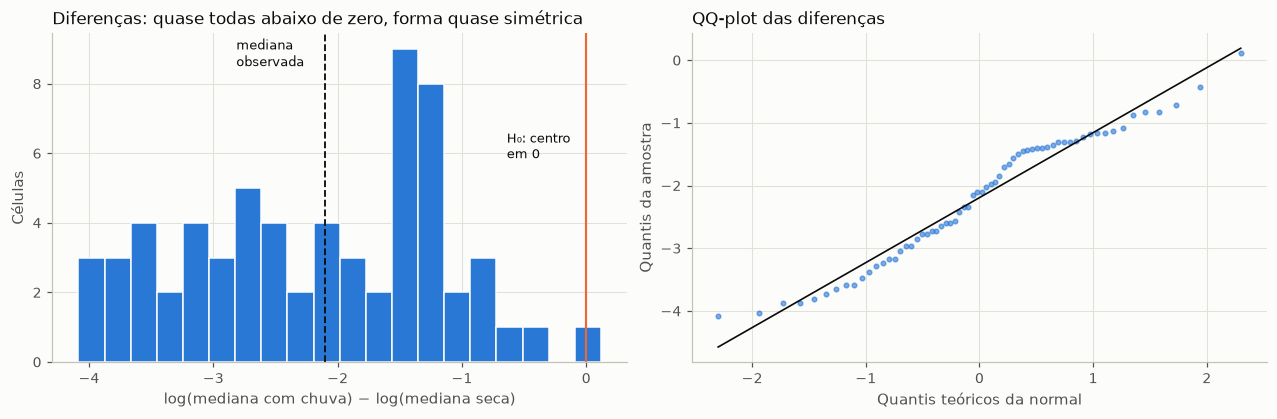

Shapiro-Wilk das diferenças: p = 0.0461
Assimetria das diferenças: -0.11 (0 = simétrica)


In [17]:
# Objetivo: Verificar normalidade e simetria das diferenças pareadas.
diferencas = pares_chuva["Log_Razao"]

fig, eixos = plt.subplots(1, 2, figsize=(11.5, 3.7), constrained_layout=True)
eixos[0].hist(diferencas, bins=20, color=AZUL, edgecolor=SUPERFICIE)
eixos[0].axvline(diferencas.median(), color=TINTA, linestyle="--", linewidth=1.2)
eixos[0].axvline(0, color=LARANJA, linewidth=1.4)
eixos[0].annotate("H₀: centro\nem 0", (0, eixos[0].get_ylim()[1] * 0.62), xytext=(-52, 0),
                  textcoords="offset points", fontsize=8.5, color=TINTA)
eixos[0].annotate("mediana\nobservada", (diferencas.median(), eixos[0].get_ylim()[1] * 0.9),
                  xytext=(-58, 0), textcoords="offset points", fontsize=8.5)
eixos[0].set(xlabel="log(mediana com chuva) − log(mediana seca)", ylabel="Células",
             title="Diferenças: quase todas abaixo de zero, forma quase simétrica")
plotar_qq(eixos[1], diferencas, "QQ-plot das diferenças")
plt.show()

print(f"Shapiro-Wilk das diferenças: p = {stats.shapiro(diferencas).pvalue:.4f}")
print(f"Assimetria das diferenças: {diferencas.skew():.2f} (0 = simétrica)")

**O que observamos:** o Shapiro-Wilk rejeita a normalidade por pouco (p ≈ 0,05), e o QQ-plot
mostra caudas um pouco curtas, então o teste t pareado não é a melhor escolha. A assimetria, por
outro lado, é praticamente nula, o que atende à suposição do Wilcoxon. Ele também é mais seguro
diante de medianas extremas de células com poucas horas de chuva.

### 6.3 Testes de Wilcoxon e do sinal

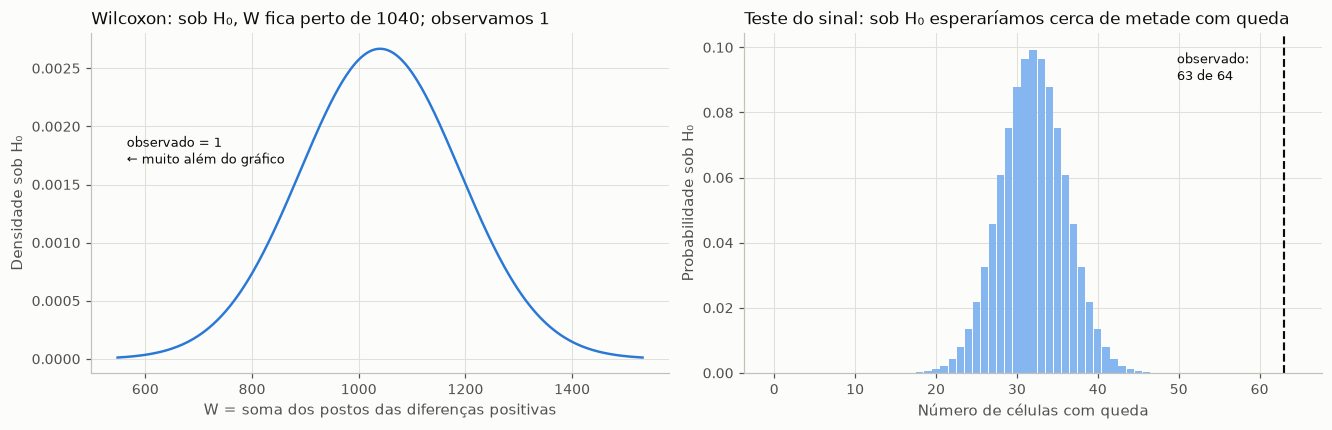

,Estatística,p-valor (unilateral)
Wilcoxon pareado,W = 1,1.8e-12
Teste do sinal,63 quedas em 64,3.5e-18


Variação mediana com chuva: -88% (correlação bisserial de postos = 1.00)


In [18]:
# Objetivo: Aplicar o Wilcoxon pareado e o teste do sinal, com as distribuições sob H0.
wilcoxon = stats.wilcoxon(diferencas, alternative="less", method="approx")
n_pares = len(diferencas)
n_quedas = int((diferencas < 0).sum())
teste_sinal = stats.binomtest(n_quedas, n_pares, p=0.5, alternative="greater")
correlacao_rank = 1 - 2 * wilcoxon.statistic / (n_pares * (n_pares + 1) / 2)
media_w = n_pares * (n_pares + 1) / 4
dp_w = np.sqrt(n_pares * (n_pares + 1) * (2 * n_pares + 1) / 24)

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
plotar_distribuicao_nula(eixos[0], wilcoxon.statistic, distribuicao=stats.norm(media_w, dp_w),
                         cauda="esquerda",
                         rotulo_estatistica="W = soma dos postos das diferenças positivas")
eixos[0].set_title("Wilcoxon: sob H₀, W fica perto de "
                   f"{media_w:.0f}; observamos {wilcoxon.statistic:.0f}")
contagens = np.arange(n_pares + 1)
probs = stats.binom(n_pares, 0.5).pmf(contagens)
eixos[1].bar(contagens, probs, color=np.where(contagens >= n_quedas, LARANJA, AZUL_CLARO),
             width=0.9)
eixos[1].axvline(n_quedas, color=TINTA, linestyle="--", linewidth=1.4)
eixos[1].annotate(f"observado:\n{n_quedas} de {n_pares}", (n_quedas, probs.max()),
                  xytext=(-70, -20), textcoords="offset points", fontsize=8.5)
eixos[1].set(xlabel="Número de células com queda", ylabel="Probabilidade sob H₀",
             title="Teste do sinal: sob H₀ esperaríamos cerca de metade com queda")
plt.show()

tabela_h3 = pd.DataFrame({
    "Estatística": [f"W = {wilcoxon.statistic:.0f}", f"{n_quedas} quedas em {n_pares}"],
    "p-valor (unilateral)": [f"{wilcoxon.pvalue:.1e}", f"{teste_sinal.pvalue:.1e}"],
}, index=["Wilcoxon pareado", "Teste do sinal"])
display(tabela_h3)
print(f"Variação mediana com chuva: {np.expm1(diferencas.median()):+.0%} "
      f"(correlação bisserial de postos = {correlacao_rank:.2f})")

### 6.4 Conclusão da Hipótese 3

| Estatística | Valor |
|---|---|
| Teste | Wilcoxon de postos sinalizados (pareado, unilateral), confirmado pelo teste do sinal |
| W e p-valor | ver tabela da Seção 6.3 (p < 10⁻¹⁰) |
| Variação mediana com chuva | cerca de −88% |
| Tamanho do efeito (correlação bisserial de postos) | próximo de 1 (máximo possível) |
| Decisão | **Rejeitamos H₀** |

**Na prática:** comparando a mesma hora na mesma estação, a chuva derruba a demanda em praticamente
todas as células (63 de 64), com queda típica de cerca de 88%. O efeito é tão consistente que resiste à
principal ressalva (as células não são totalmente independentes, pois um mesmo dia chuvoso entra em
várias horas): mesmo que a amostra efetiva fosse de apenas 20 células, 20 quedas em 20 dariam p
≈ 10⁻⁶ no teste do sinal.

**Para a Etapa 3:** como a queda é multiplicativa (uma porcentagem, e não um número fixo de
bicicletas), ela combina naturalmente com uma resposta em **log** e um indicador `Is_Rainy`.

## Seção 7 – Hipótese 4: O Calor Excessivo Reduz a Demanda?

Na Etapa 1, a demanda subia com a temperatura até cerca de 25–30 °C e depois caía. Isso levanta uma
pergunta que a correlação geral não responde: **a relação muda de sinal nos dias mais quentes?**
Testamos dois trechos separadamente, no nível diário:

- **H4a (dias amenos, temperatura média < 25 °C):** H₀: ρ = 0; H₁: ρ > 0 (a demanda cresce com a
  temperatura).
- **H4b (dias quentes, ≥ 25 °C):** H₀: ρ = 0; H₁: ρ < 0 (a demanda cai com mais calor).

**Nível de significância:** como fazemos dois testes para responder a uma pergunta, aplicamos a
correção de Bonferroni: α = 0,05 / 2 = 0,025 em cada.

**Justificativa – por que dias e por que só dias secos no trecho quente.** No nível horário, as
horas mais quentes são as do início da tarde, que têm menos demanda que as 18h por causa do
horário, e não do calor: a média diária remove esse efeito. Além disso, os dias quentes de
julho e agosto também são os de chuvas de monção, e a H3 mostrou que a chuva derruba a demanda.
Para não atribuir ao calor um efeito da chuva, H4b usa só dias **sem chuva** registrada.

### 7.1 Os dados

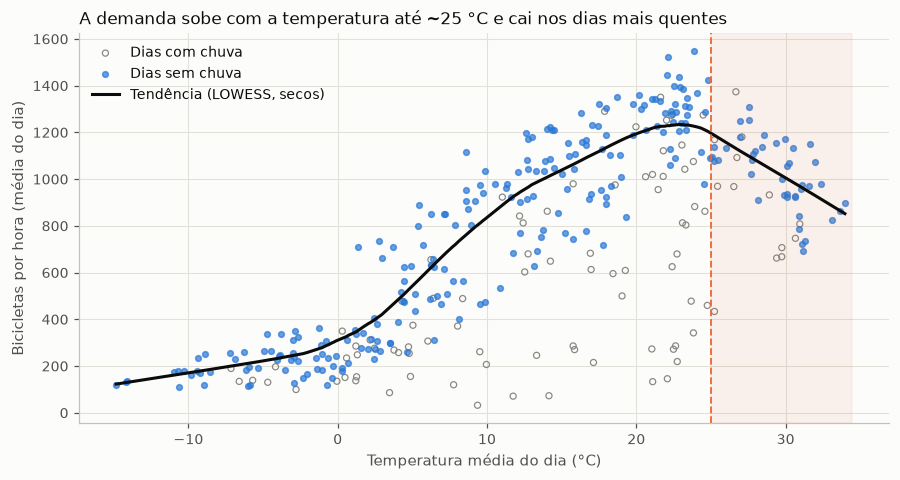

In [19]:
# Objetivo: Visualizar a demanda diária contra a temperatura, destacando os dias com chuva.
LIMIAR_CALOR = 25
dias_secos = df_dia[df_dia["Chuva_Total"] == 0]
dias_chuva = df_dia[df_dia["Chuva_Total"] > 0]
curva = lowess(dias_secos["Media_Horaria"], dias_secos["Temp_Media"], frac=0.35)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.scatter(dias_chuva["Temp_Media"], dias_chuva["Media_Horaria"], s=16, facecolor="none",
           edgecolor=CINZA, linewidth=0.8, label="Dias com chuva")
ax.scatter(dias_secos["Temp_Media"], dias_secos["Media_Horaria"], s=14, color=AZUL, alpha=0.7,
           label="Dias sem chuva")
ax.plot(curva[:, 0], curva[:, 1], color=TINTA, linewidth=2, label="Tendência (LOWESS, secos)")
ax.axvspan(LIMIAR_CALOR, df_dia["Temp_Media"].max() + 0.5, color=LARANJA, alpha=0.08)
ax.axvline(LIMIAR_CALOR, color=LARANJA, linewidth=1.2, linestyle="--")
ax.annotate("trecho H4b\n(≥ 25 °C)", (LIMIAR_CALOR + 0.4, 1650), fontsize=8.5, color=TINTA)
ax.set(xlabel="Temperatura média do dia (°C)", ylabel="Bicicletas por hora (média do dia)",
       title="A demanda sobe com a temperatura até ~25 °C e cai nos dias mais quentes")
ax.legend(loc="upper left")
plt.show()

### 7.2 Escolha do teste: Pearson ou Spearman?

A correlação de Pearson mede associação **linear** e seu teste supõe que as duas variáveis tenham,
juntas, distribuição normal. A correlação de **Spearman** mede associação **monotônica** (sempre
crescente ou sempre decrescente, não necessariamente em linha reta) e usa apenas os postos, sem
supor normalidade. Verificamos a normalidade das variáveis em cada trecho.

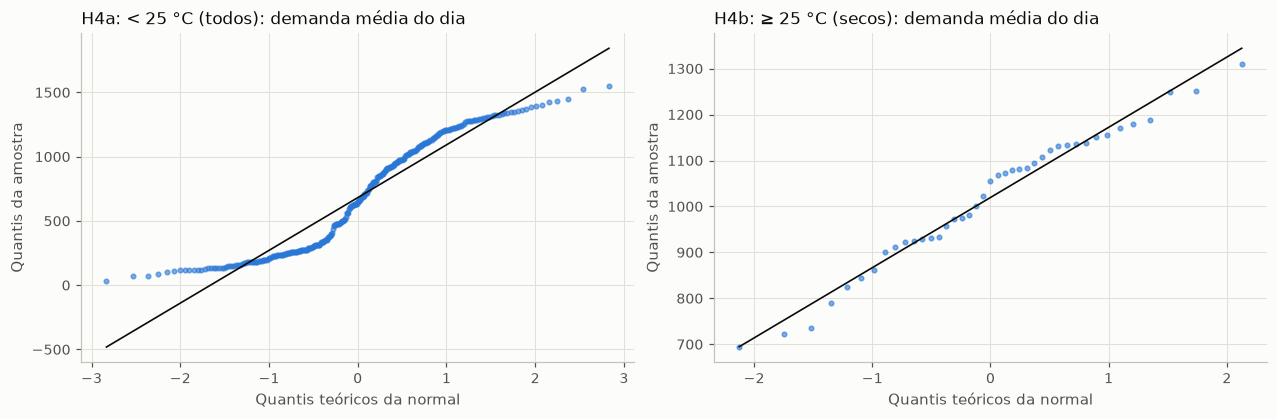

,dias,Shapiro demanda (p),Shapiro temperatura (p)
H4a: < 25 °C (todos),299,0.0000,0.0000
H4b: ≥ 25 °C (secos),41,0.4539,0.1956


In [20]:
# Objetivo: Verificar a normalidade das variáveis em cada trecho de temperatura.
trechos = {
    "H4a: < 25 °C (todos)": df_dia[df_dia["Temp_Media"] < LIMIAR_CALOR],
    "H4b: ≥ 25 °C (secos)": dias_secos[dias_secos["Temp_Media"] >= LIMIAR_CALOR],
}

fig, eixos = plt.subplots(1, 2, figsize=(11.5, 3.7), constrained_layout=True)
linhas = {}
for ax, (nome, dados) in zip(eixos, trechos.items()):
    plotar_qq(ax, dados["Media_Horaria"], f"{nome}: demanda média do dia")
    linhas[nome] = {
        "dias": len(dados),
        "Shapiro demanda (p)": stats.shapiro(dados["Media_Horaria"]).pvalue,
        "Shapiro temperatura (p)": stats.shapiro(dados["Temp_Media"]).pvalue,
    }
plt.show()
display(pd.DataFrame(linhas).T.style.format({"dias": "{:.0f}", "Shapiro demanda (p)": "{:.4f}",
                                             "Shapiro temperatura (p)": "{:.4f}"}))

**O que observamos:** no trecho ameno, a normalidade é claramente rejeitada (o QQ-plot tem forma
de "S", e a relação com a temperatura é curva no gráfico da Seção 7.1). No trecho quente, a
normalidade não é rejeitada, mas com 41 dias o Shapiro-Wilk tem pouco poder para detectar desvios. Por isso, usamos **Spearman** nos dois trechos,
mostrando Pearson apenas como comparação. Para H4b, que tem poucos dias, também calculamos o
p-valor por **permutação**: embaralhamos a demanda entre os dias 10.000 vezes e vemos com que
frequência surge uma correlação tão negativa quanto a observada.

### 7.3 Correlação de Spearman nos dois trechos

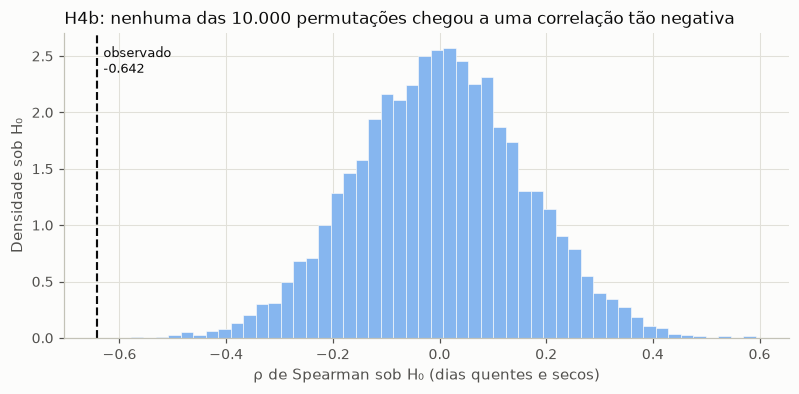

,dias,Spearman ρ,p (unilateral),Pearson r,p (permutação),"Rejeita H0 (α = 0,025)"
H4a: < 25 °C (todos),299,0.78,5.4e-62,0.78,–,True
H4b: ≥ 25 °C (secos),41,-0.64,3.1e-06,-0.60,1.0e-04,True


In [21]:
# Objetivo: Calcular Spearman (e Pearson) em cada trecho e o teste de permutação em H4b.
def correlacao_permutacao(x, y, n_permutacoes, gerador):
    '''Gera a distribuição de Spearman sob H0 embaralhando y.

    Parâmetros:
        x (array): primeira variável.
        y (array): segunda variável.
        n_permutacoes (int): número de permutações.
        gerador (numpy.random.Generator): gerador aleatório com semente fixa.

    Retorna:
        ndarray com as correlações de Spearman simuladas sob H0.
    '''
    postos_x = stats.rankdata(x)
    postos_y = stats.rankdata(y)
    return np.array([np.corrcoef(postos_x, gerador.permutation(postos_y))[0, 1]
                     for _ in range(n_permutacoes)])


alternativas = {"H4a: < 25 °C (todos)": "greater", "H4b: ≥ 25 °C (secos)": "less"}
resultados_h4 = {}
for nome, dados in trechos.items():
    spearman = stats.spearmanr(dados["Temp_Media"], dados["Media_Horaria"],
                               alternative=alternativas[nome])
    pearson = stats.pearsonr(dados["Temp_Media"], dados["Media_Horaria"])
    resultados_h4[nome] = {"dias": len(dados), "Spearman ρ": spearman.statistic,
                           "p (unilateral)": spearman.pvalue, "Pearson r": pearson.statistic}

quentes = trechos["H4b: ≥ 25 °C (secos)"]
rho_quente = resultados_h4["H4b: ≥ 25 °C (secos)"]["Spearman ρ"]
nulas_rho = correlacao_permutacao(quentes["Temp_Media"], quentes["Media_Horaria"],
                                  N_PERMUTACOES, rng)
p_perm_rho = (1 + np.sum(nulas_rho <= rho_quente)) / (N_PERMUTACOES + 1)
resultados_h4["H4b: ≥ 25 °C (secos)"]["p (permutação)"] = p_perm_rho

fig, ax = plt.subplots(figsize=(8.5, 3.6))
plotar_distribuicao_nula(ax, rho_quente, amostras_nulas=nulas_rho, cauda="esquerda",
                         rotulo_estatistica="ρ de Spearman sob H₀ (dias quentes e secos)")
ax.set_title("H4b: nenhuma das 10.000 permutações chegou a uma correlação tão negativa")
plt.show()

tabela_h4 = pd.DataFrame(resultados_h4).T
tabela_h4["Rejeita H0 (α = 0,025)"] = tabela_h4["p (unilateral)"] < ALFA / 2
display(tabela_h4.style.format({"dias": "{:.0f}", "Spearman ρ": "{:.2f}", "Pearson r": "{:.2f}",
                                "p (unilateral)": "{:.1e}", "p (permutação)": "{:.1e}"},
                               na_rep="–"))

### 7.4 O resultado depende do limiar de 25 °C?

**Justificativa.** O limiar de 25 °C foi sugerido pelos próprios dados da Etapa 1. Escolher um corte
depois de olhar os dados pode produzir um resultado "sob medida". Para verificar que a conclusão não
depende dessa escolha, repetimos o cálculo para limiares de 20 °C a 28 °C, com intervalos de
confiança de 95% obtidos por *bootstrap* (reamostragem dos dias com reposição, 2.000 vezes).

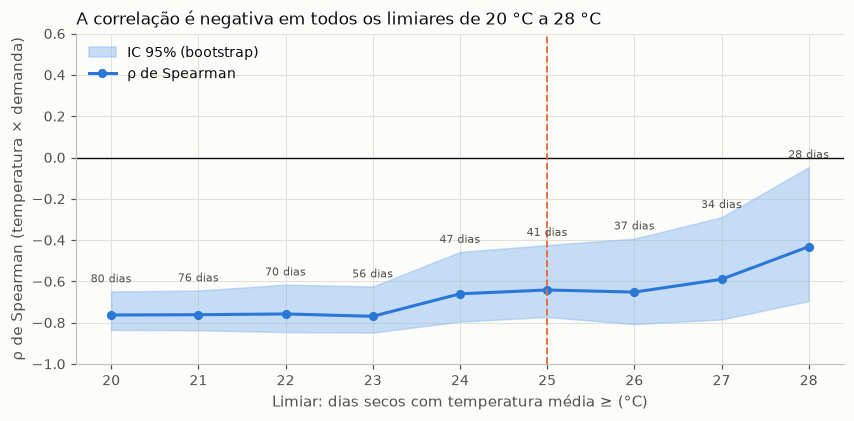

,limiar,dias,rho,ic_inf,ic_sup
0,20,80,-0.76,-0.83,-0.65
1,21,76,-0.76,-0.84,-0.64
2,22,70,-0.76,-0.85,-0.62
3,23,56,-0.77,-0.85,-0.63
4,24,47,-0.66,-0.79,-0.46
5,25,41,-0.64,-0.77,-0.42
6,26,37,-0.65,-0.81,-0.39
7,27,34,-0.59,-0.78,-0.29
8,28,28,-0.43,-0.70,-0.05


In [22]:
# Objetivo: Calcular Spearman com IC por bootstrap para vários limiares de temperatura.
def spearman_bootstrap(x, y, n_reamostras, gerador):
    '''Estima o intervalo de confiança de 95% do ρ de Spearman por bootstrap.

    Parâmetros:
        x (ndarray): primeira variável.
        y (ndarray): segunda variável.
        n_reamostras (int): número de reamostras com reposição.
        gerador (numpy.random.Generator): gerador aleatório com semente fixa.

    Retorna:
        Tupla (limite inferior, limite superior).
    '''
    indices = gerador.integers(0, len(x), size=(n_reamostras, len(x)))
    valores = [stats.spearmanr(x[i], y[i]).statistic for i in indices]
    return tuple(np.nanpercentile(valores, [2.5, 97.5]))


linhas = []
for limiar in range(20, 29):
    acima = dias_secos[dias_secos["Temp_Media"] >= limiar]
    x, y = acima["Temp_Media"].to_numpy(), acima["Media_Horaria"].to_numpy()
    inferior, superior = spearman_bootstrap(x, y, 2000, rng)
    linhas.append({"limiar": limiar, "dias": len(acima),
                   "rho": stats.spearmanr(x, y).statistic, "ic_inf": inferior,
                   "ic_sup": superior})
sensibilidade = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(9, 3.9))
ax.fill_between(sensibilidade["limiar"], sensibilidade["ic_inf"], sensibilidade["ic_sup"],
                color=AZUL_CLARO, alpha=0.45, label="IC 95% (bootstrap)")
ax.plot(sensibilidade["limiar"], sensibilidade["rho"], color=AZUL, marker="o", ms=5,
        label="ρ de Spearman")
ax.axhline(0, color=TINTA, linewidth=0.9)
ax.axvline(LIMIAR_CALOR, color=LARANJA, linestyle="--", linewidth=1.2)
for _, linha in sensibilidade.iterrows():
    ax.annotate(f"{linha['dias']:.0f} dias", (linha["limiar"], linha["ic_sup"]),
                xytext=(0, 6), textcoords="offset points", ha="center", fontsize=7.5,
                color=TINTA_SECUNDARIA)
ax.set(xlabel="Limiar: dias secos com temperatura média ≥ (°C)",
       ylabel="ρ de Spearman (temperatura × demanda)", ylim=(-1, 0.6),
       title="A correlação é negativa em todos os limiares de 20 °C a 28 °C")
ax.legend(loc="upper left")
plt.show()

display(sensibilidade.round(2))

### 7.5 Conclusão da Hipótese 4

| Trecho | Teste | ρ de Spearman | p-valor | Decisão (α = 0,025) |
|---|---|---|---|---|
| H4a: < 25 °C | Spearman unilateral (ρ > 0) | ver tabela da Seção 7.3 (≈ 0,78) | < 10⁻⁶⁰ | **Rejeitamos H₀** |
| H4b: ≥ 25 °C, secos | Spearman unilateral (ρ < 0) + permutação | ver tabela da Seção 7.3 (≈ −0,64) | ≈ 3 × 10⁻⁶ (permutação: ≤ 10⁻⁴) | **Rejeitamos H₀** |

**Na prática:** a temperatura tem uma relação **em forma de arco** com a demanda. Nos dias amenos,
mais calor significa mais bicicletas (associação forte); nos dias quentes e secos, cada grau a mais
está associado a **menos** bicicletas. A análise de sensibilidade mostra que isso não é um artefato
do corte em 25 °C.

**Limitações:** os dias mais quentes estão concentrados no fim de julho e começo de agosto de 2018,
período de férias escolares e de uma onda de calor. Com um único ano de dados, não conseguimos
separar totalmente o efeito do calor do efeito do período. Além disso, correlação não é
causalidade.

**Para a Etapa 3:** a relação não é linear, então um termo **quadrático** em `Temperature`, ou
faixas de temperatura, deve ser testado no modelo.

## Seção 8 – Fechamento

### 8.1 Tabela resumo

A tabela abaixo é montada a partir dos resultados calculados nas seções anteriores.

In [23]:
# Objetivo: Reunir em uma tabela os resultados de todas as hipóteses.
resumo = pd.DataFrame([
    {"Hipótese": "H1 – Estações", "Teste": "Kruskal-Wallis (dias)",
     "Estatística": f"H = {h_kw:.1f}", "p-valor": p_kw,
     "Tamanho do efeito": f"ε² = {epsilon2:.2f}"},
    {"Hipótese": "H2 – Feriado | estação", "Teste": "ANOVA 2 fatores, log (dias)",
     "Estatística": f"F = {anova_h2.loc['Holiday', 'F']:.2f}",
     "p-valor": anova_h2.loc["Holiday", "PR(>F)"],
     "Tamanho do efeito": f"{np.expm1(efeito_log):+.0%} na demanda"},
    {"Hipótese": "H2 – Feriado | estação", "Teste": "Permutação estratificada (dias)",
     "Estatística": f"dif. log = {dif_feriado:.3f}", "p-valor": p_perm_feriado,
     "Tamanho do efeito": f"{np.expm1(dif_feriado):+.0%} na demanda"},
    {"Hipótese": "H3 – Chuva | hora e estação", "Teste": "Wilcoxon pareado (células)",
     "Estatística": f"W = {wilcoxon.statistic:.0f}", "p-valor": wilcoxon.pvalue,
     "Tamanho do efeito": f"{np.expm1(diferencas.median()):+.0%} na demanda"},
    {"Hipótese": "H4a – Temperatura < 25 °C", "Teste": "Spearman unilateral (dias)",
     "Estatística": f"ρ = {resultados_h4['H4a: < 25 °C (todos)']['Spearman ρ']:.2f}",
     "p-valor": resultados_h4["H4a: < 25 °C (todos)"]["p (unilateral)"],
     "Tamanho do efeito": "ρ forte e positivo"},
    {"Hipótese": "H4b – Temperatura ≥ 25 °C", "Teste": "Spearman unilateral (dias secos)",
     "Estatística": f"ρ = {rho_quente:.2f}",
     "p-valor": resultados_h4["H4b: ≥ 25 °C (secos)"]["p (unilateral)"],
     "Tamanho do efeito": "ρ moderado/forte e negativo"},
])
alfas = [ALFA, ALFA, ALFA, ALFA, ALFA / 2, ALFA / 2]
resumo["α"] = alfas
resumo["Decisão"] = np.where(resumo["p-valor"] < resumo["α"], "Rejeita H₀", "Não rejeita H₀")
display(resumo.style.format({"p-valor": "{:.1e}", "α": "{:.3f}"}).hide(axis="index"))

Hipótese,Teste,Estatística,p-valor,Tamanho do efeito,α,Decisão
H1 – Estações,Kruskal-Wallis (dias),H = 187.1,2.6e-40,ε² = 0.53,0.050,Rejeita H₀
H2 – Feriado | estação,"ANOVA 2 fatores, log (dias)",F = 2.55,1.1e-01,-18% na demanda,0.050,Não rejeita H₀
H2 – Feriado | estação,Permutação estratificada (dias),dif. log = -0.200,7.7e-02,-18% na demanda,0.050,Não rejeita H₀
H3 – Chuva | hora e estação,Wilcoxon pareado (células),W = 1,1.8e-12,-88% na demanda,0.050,Rejeita H₀
H4a – Temperatura < 25 °C,Spearman unilateral (dias),ρ = 0.78,5.4e-62,ρ forte e positivo,0.025,Rejeita H₀
H4b – Temperatura ≥ 25 °C,Spearman unilateral (dias secos),ρ = -0.64,3.1e-06,ρ moderado/forte e negativo,0.025,Rejeita H₀


### 8.2 Uma visão única: força da evidência e o efeito da unidade de análise

O gráfico mostra o p-valor de cada teste em escala logarítmica (quanto mais à direita, mais forte a
evidência contra H₀). Para cada hipótese, mostramos também o teste **ingênuo** com horas
independentes e sem controles, para mostrar quanto a escolha da unidade e dos controles muda a
conclusão.

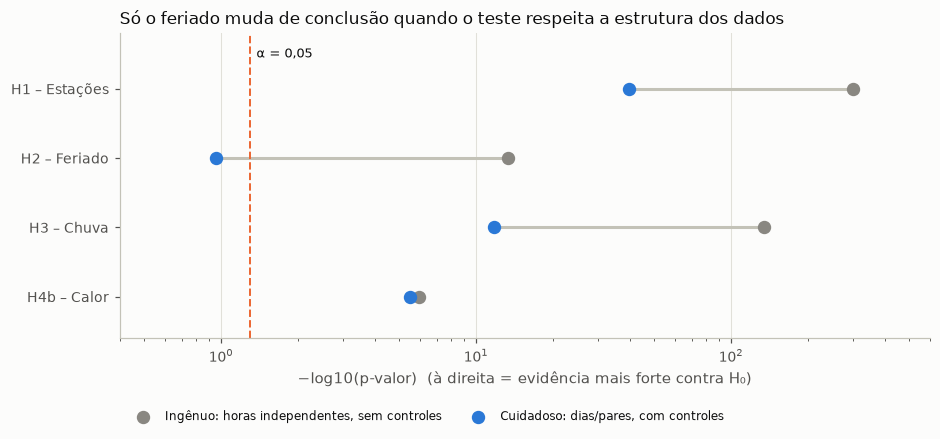

,Ingênuo (horas),Cuidadoso
H1 – Estações,0.0e+00,2.6e-40
H2 – Feriado,4.8e-14,1.1e-01
H3 – Chuva,7.7e-136,1.8e-12
H4b – Calor,1.0e-06,3.1e-06


In [24]:
# Objetivo: Comparar a força da evidência dos testes cuidadosos com a dos testes ingênuos.
def menos_log10(p):
    '''Converte um p-valor para −log10(p), limitando valores numericamente nulos.

    Parâmetros:
        p (float): p-valor.

    Retorna:
        float com −log10(p), limitado a 300.
    '''
    return min(-np.log10(max(p, 1e-300)), 300)


chuva_ingenuo = stats.mannwhitneyu(df_op.loc[df_op["Is_Rainy"] == 1, ALVO],
                                   df_op.loc[df_op["Is_Rainy"] == 0, ALVO],
                                   alternative="less").pvalue
estacao_ingenuo = stats.kruskal(*[df_op.loc[df_op["Seasons"] == s, ALVO]
                                  for s in ORDEM_ESTACOES]).pvalue
calor_ingenuo = stats.spearmanr(
    df_op.loc[df_op["Temperature"] >= LIMIAR_CALOR, "Temperature"],
    df_op.loc[df_op["Temperature"] >= LIMIAR_CALOR, ALVO], alternative="less").pvalue

comparacao = pd.DataFrame({
    "Ingênuo (horas)": [estacao_ingenuo, teste_ingenuo.pvalue, chuva_ingenuo, calor_ingenuo],
    "Cuidadoso": [p_kw, anova_h2.loc["Holiday", "PR(>F)"], wilcoxon.pvalue,
                  resultados_h4["H4b: ≥ 25 °C (secos)"]["p (unilateral)"]],
}, index=["H1 – Estações", "H2 – Feriado", "H3 – Chuva", "H4b – Calor"])
pontos = comparacao.map(menos_log10)

fig, ax = plt.subplots(figsize=(9.5, 3.6))
posicoes = np.arange(len(pontos))[::-1]
ax.hlines(posicoes, pontos.min(axis=1), pontos.max(axis=1), color=CINZA_CLARO, linewidth=2)
ax.scatter(pontos["Ingênuo (horas)"], posicoes, s=60, color=CINZA, zorder=3,
           label="Ingênuo: horas independentes, sem controles")
ax.scatter(pontos["Cuidadoso"], posicoes, s=60, color=AZUL, zorder=3,
           label="Cuidadoso: dias/pares, com controles")
ax.axvline(-np.log10(ALFA), color=LARANJA, linestyle="--", linewidth=1.3)
ax.annotate("α = 0,05", (-np.log10(ALFA), posicoes.max() + 0.45), xytext=(4, 0),
            textcoords="offset points", fontsize=8.5)
ax.set(xscale="log", xlim=(0.4, 600), yticks=posicoes, yticklabels=pontos.index,
       xlabel="−log10(p-valor)  (à direita = evidência mais forte contra H₀)",
       ylim=(-0.6, len(pontos) - 0.2),
       title="Só o feriado muda de conclusão quando o teste respeita a estrutura dos dados")
ax.legend(loc="upper left", fontsize=8, bbox_to_anchor=(0, -0.2), ncol=2)
ax.grid(axis="y", visible=False)
plt.show()

display(comparacao.map(lambda p: f"{p:.1e}"))

**O que observamos:** em estação, chuva e calor, a evidência é tão forte que sobrevive a qualquer
abordagem; o teste cuidadoso apenas fornece um p-valor mais realista. No feriado, a conclusão
**muda de lado** da linha de α: o teste ingênuo "descobre" um efeito que desaparece quando
controlamos a estação e usamos o dia como unidade. Esse é o principal aprendizado desta etapa.

### 8.3 Conclusões e implicações para a Etapa 3

1. **Estação (H1):** efeito grande e confirmado. Entrará no modelo como `Seasons` ou `Month`,
   verificando a sobreposição com a temperatura.
2. **Feriado (H2):** sem evidência de efeito depois de controlar a estação. Variável candidata
   fraca; vale testar apenas em interação com a hora (feriados perdem os picos de deslocamento).
3. **Chuva (H3):** queda de cerca de 88% na mesma hora e estação, com efeito **multiplicativo**.
   Sugere usar `Is_Rainy` e modelar a demanda em escala log.
4. **Temperatura (H4):** relação em arco, positiva até ~25 °C e negativa acima. Sugere um termo
   quadrático em `Temperature`.
5. **Metodologia:** as observações horárias são dependentes. Na Etapa 3, isso aparecerá como
   autocorrelação nos resíduos, que deverá ser avaliada; os p-valores da ANOVA do modelo devem ser
   lidos com essa ressalva.